1 - Libraries and configuration

In [2]:
# ============================================================
# SECTION 1 — IMPORT LIBRARIES AND CONFIGURATION
# ============================================================

# 1.1 Import libraries

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense
from tensorflow.keras.callbacks import EarlyStopping

# ------------------------------------------------------------
# 1.2 Set random seeds for reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# ------------------------------------------------------------
# 1.3 Dataset locations
# ------------------------------------------------------------

# Place the four CSV files in the same folder as your notebook.

DATA_FILES = {
    "Client1": "Client1(original).csv",
    "Client2": "Client2(original).csv",
    "Client3": "Client3(original).csv",
    "Switch":  "Switch(original).csv"
}

# ------------------------------------------------------------
# 1.4 LSTM configuration
# ------------------------------------------------------------

SEQUENCE_LENGTH = 30

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 50
BATCH_SIZE = 32

LEARNING_RATE = 0.001

ANOMALY_PERCENTILE = 99

# ------------------------------------------------------------
# 1.5 Create output folders
# ------------------------------------------------------------

OUTPUT_DIR = Path("LSTM_Results")
MODEL_DIR = OUTPUT_DIR / "Models"
RESULTS_DIR = OUTPUT_DIR / "Anomaly_Results"
PLOTS_DIR = OUTPUT_DIR / "Plots"

for folder in [MODEL_DIR, RESULTS_DIR, PLOTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1.6 Check dataset availability
# ------------------------------------------------------------

print("=" * 55)
print("LSTM AUTOENCODER — CAPSTONE PROJECT")
print("=" * 55)

print("\nTensorFlow Version:", tf.__version__)
print("Sequence Length:", SEQUENCE_LENGTH)
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Anomaly Percentile:", ANOMALY_PERCENTILE)

print("\nSuccessfully created output directories")


LSTM AUTOENCODER — CAPSTONE PROJECT

TensorFlow Version: 2.21.0
Sequence Length: 30
Epochs: 50
Batch Size: 32
Anomaly Percentile: 99

Successfully created output directories


2 - Retrieve telemetry

In [3]:
# ============================================================
# SECTION 2 — LOAD, CLEAN AND PRESERVE ORIGINAL DATA
# ============================================================

# ------------------------------------------------------------
# 2.1 Define original metrics
# ------------------------------------------------------------

ORIGINAL_METRICS = [
    "cpu_pct",
    "temperature_c",
    "latency_ms",
    "packet_loss_pct",
    "disk_usage_pct",
    "throughput_bytes_per_sec",
    "packet_error_rate_pct"
]

SWITCH_METRICS = [
    "cpu_pct",
    "free_memory",
    "temperature",
    "power_supply_state"
]

# ------------------------------------------------------------
# 2.2 Create storage for original and cleaned datasets
# ------------------------------------------------------------

original_datasets = {}
datasets = {}
device_metrics = {}

cleaning_summary = []

ORIGINAL_DIR = OUTPUT_DIR / "Original_Data"
CLEANED_DIR = OUTPUT_DIR / "Cleaned_Data"

ORIGINAL_DIR.mkdir(parents=True, exist_ok=True)
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2.3 Process each device
# ------------------------------------------------------------

for device, filename in DATA_FILES.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    # Load wide-format CSV
    df = pd.read_csv(filename, low_memory=False)

    # Convert timestamps to UTC
    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True,
        errors="coerce"
    )

    # Check invalid timestamps before removing them
    invalid_timestamps = df["timestamp"].isna().sum()

    # Remove invalid timestamps and sort chronologically
    df = df.dropna(subset=["timestamp"])
    df = df.sort_values("timestamp").reset_index(drop=True)

    # --------------------------------------------------------
    # 2.4 Select original collected metrics
    # --------------------------------------------------------

    if device == "Switch":
        metrics = SWITCH_METRICS
    else:
        metrics = ORIGINAL_METRICS

    missing_columns = [
        metric for metric in metrics
        if metric not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{device} is missing: {missing_columns}"
        )

    df = df[["timestamp"] + metrics].copy()

    # Convert selected metrics to numeric
    for metric in metrics:
        df[metric] = pd.to_numeric(
            df[metric],
            errors="coerce"
        )

    # --------------------------------------------------------
    # 2.5 Preserve original observations
    # --------------------------------------------------------

    original_datasets[device] = df.copy()
    device_metrics[device] = metrics.copy()

    original_rows = len(df)

    original_missing = int(
        df[metrics].isna().sum().sum()
    )

    original_file = (
        ORIGINAL_DIR / f"{device}_Original.csv"
    )

    df.to_csv(original_file, index=False)

    # --------------------------------------------------------
    # 2.6 Create cleaned dataset
    # --------------------------------------------------------

    cleaned = df.copy()

    removed_latency_period = 0
    last_missing_time = None

    # Remove everything up to the last missing latency
    # for Raspberry Pi devices only
    if device != "Switch":

        missing_latency = cleaned["latency_ms"].isna()

        if missing_latency.any():

            last_missing_index = np.flatnonzero(
                missing_latency.to_numpy()
            )[-1]

            last_missing_time = cleaned.loc[
                last_missing_index, "timestamp"
            ]

            removed_latency_period = last_missing_index + 1

            cleaned = cleaned.iloc[
                last_missing_index + 1:
            ].copy()

    # Remove any remaining observations with missing metrics
    before_dropna = len(cleaned)

    cleaned = cleaned.dropna(
        subset=metrics
    ).reset_index(drop=True)

    removed_missing_rows = before_dropna - len(cleaned)

    # Check for duplicate timestamps
    duplicate_count = int(
        cleaned["timestamp"].duplicated().sum()
    )

    if duplicate_count > 0:
        raise ValueError(
            f"{device} has {duplicate_count} duplicate timestamps."
        )

    # --------------------------------------------------------
    # 2.7 Store and save cleaned dataset
    # --------------------------------------------------------

    datasets[device] = cleaned

    cleaned_file = (
        CLEANED_DIR / f"{device}_Cleaned.csv"
    )

    cleaned.to_csv(cleaned_file, index=False)

    # --------------------------------------------------------
    # 2.8 Record cleaning information
    # --------------------------------------------------------

    cleaning_summary.append({
        "Device": device,
        "Original_Rows": original_rows,
        "Invalid_Timestamps": int(invalid_timestamps),
        "Original_Missing_Values": original_missing,
        "Removed_Initial_Period": removed_latency_period,
        "Removed_Incomplete_Rows": removed_missing_rows,
        "Remaining_Rows": len(cleaned),
        "Number_of_Metrics": len(metrics),
        "Last_Missing_Latency": last_missing_time,
        "Cleaned_Start": (
            cleaned["timestamp"].min()
            if not cleaned.empty else pd.NaT
        ),
        "Cleaned_End": (
            cleaned["timestamp"].max()
            if not cleaned.empty else pd.NaT
        )
    })

    # --------------------------------------------------------
    # 2.9 Display device results
    # --------------------------------------------------------

    print("\nOriginal observations:", original_rows)
    print("Original missing values:", original_missing)

    print("\nCleaning:")
    print("Removed initial period:", removed_latency_period)
    print("Removed incomplete rows:", removed_missing_rows)

    if last_missing_time is not None:
        print("Last missing latency:", last_missing_time)

    print("\nCleaned observations:", len(cleaned))
    print("Number of metrics:", len(metrics))

    print("\nSelected Metrics:")
    for metric in metrics:
        print(" -", metric)

    print("\nRemaining missing values:")
    print(cleaned[metrics].isna().sum().to_string())

    intervals = (
        cleaned["timestamp"]
        .diff()
        .dt.total_seconds()
        .dropna()
    )

    if not intervals.empty:
        print("\nSampling Intervals:")
        print(f"Median: {intervals.median():.2f} seconds")
        print(f"Mean:   {intervals.mean():.2f} seconds")
        print(f"Max:    {intervals.max():.2f} seconds")

    print("\nFirst 3 cleaned rows:")
    print(cleaned.head(3).to_string(index=False))

# ============================================================
# 2.10 SAVE FINAL CLEANING SUMMARY
# ============================================================

summary_df = pd.DataFrame(cleaning_summary)

summary_file = OUTPUT_DIR / "Cleaning_Summary.csv"
summary_df.to_csv(summary_file, index=False)

print("\n" + "=" * 60)
print("SECTION 2 COMPLETE")
print("=" * 60)

print("\nFinal Dataset Summary:")
print(
    summary_df[
        [
            "Device",
            "Original_Rows",
            "Removed_Initial_Period",
            "Removed_Incomplete_Rows",
            "Remaining_Rows",
            "Number_of_Metrics"
        ]
    ].to_string(index=False)
)

print("\nFiles saved to:", OUTPUT_DIR.resolve())


DEVICE: Client1

Original observations: 185055
Original missing values: 13824

Cleaning:
Removed initial period: 19346
Removed incomplete rows: 3
Last missing latency: 2026-09-28 01:23:29.194491+00:00

Cleaned observations: 165706
Number of metrics: 7

Selected Metrics:
 - cpu_pct
 - temperature_c
 - latency_ms
 - packet_loss_pct
 - disk_usage_pct
 - throughput_bytes_per_sec
 - packet_error_rate_pct

Remaining missing values:
cpu_pct                     0
temperature_c               0
latency_ms                  0
packet_loss_pct             0
disk_usage_pct              0
throughput_bytes_per_sec    0
packet_error_rate_pct       0

Sampling Intervals:
Median: 14.07 seconds
Mean:   13.63 seconds
Max:    168.79 seconds

First 3 cleaned rows:
                       timestamp  cpu_pct  temperature_c  latency_ms  packet_loss_pct  disk_usage_pct  throughput_bytes_per_sec  packet_error_rate_pct
2026-09-28 01:23:56.842664+00:00      0.0           34.5       0.575                0            

3 - Clean and preprocess

In [4]:
# ============================================================
# SECTION 3 — DATA SPLITTING AND NORMALISATION
# ============================================================

from sklearn.preprocessing import StandardScaler
import joblib

# ------------------------------------------------------------
# 3.1 Configuration
# ------------------------------------------------------------

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

assert np.isclose(
    TRAIN_RATIO + VAL_RATIO + TEST_RATIO, 1.0
), "Data split ratios must add up to 1."

# Store results for Section 4
split_data = {}
scalers = {}

# ------------------------------------------------------------
# 3.2 Process each device independently
# ------------------------------------------------------------

for device, df in datasets.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    metrics = device_metrics[device]

    # Validate cleaned dataset
    if df.empty:
        raise ValueError(f"{device} has no observations.")

    if df[metrics].isna().any().any():
        raise ValueError(f"{device} contains missing values.")

    if not df["timestamp"].is_monotonic_increasing:
        raise ValueError(f"{device} timestamps are not sorted.")

    if df["timestamp"].duplicated().any():
        raise ValueError(f"{device} has duplicate timestamps.")

    # --------------------------------------------------------
    # 3.3 Split chronologically (70% / 15% / 15%)
    # --------------------------------------------------------

    total_rows = len(df)

    train_end = int(total_rows * TRAIN_RATIO)
    val_end = int(
        total_rows * (TRAIN_RATIO + VAL_RATIO)
    )

    train_df = df.iloc[:train_end].copy()
    val_df = df.iloc[train_end:val_end].copy()
    test_df = df.iloc[val_end:].copy()

    # --------------------------------------------------------
    # 3.4 Normalise using training data ONLY
    # --------------------------------------------------------

    scaler = StandardScaler()

    X_train = scaler.fit_transform(train_df[metrics])
    X_val = scaler.transform(val_df[metrics])
    X_test = scaler.transform(test_df[metrics])

    # TensorFlow uses float32 efficiently
    X_train = X_train.astype(np.float32)
    X_val = X_val.astype(np.float32)
    X_test = X_test.astype(np.float32)

    # --------------------------------------------------------
    # 3.5 Validate normalised data
    # --------------------------------------------------------

    for name, values in [
        ("Train", X_train),
        ("Validation", X_val),
        ("Test", X_test)
    ]:

        nan_count = np.isnan(values).sum()
        inf_count = np.isinf(values).sum()

        print(
            f"{name}: NaN={nan_count}, Inf={inf_count}"
        )

        # Stop if invalid numbers are detected
        if not np.isfinite(values).all():
            raise ValueError(
                f"{device}: Invalid values found in {name}!"
            )

    # --------------------------------------------------------
    # 3.6 Store results for sequence generation
    # --------------------------------------------------------

    split_data[device] = {
        "train": X_train,
        "val": X_val,
        "test": X_test,

        "train_timestamps": train_df["timestamp"].to_numpy(),
        "val_timestamps": val_df["timestamp"].to_numpy(),
        "test_timestamps": test_df["timestamp"].to_numpy(),

        "metrics": metrics
    }

    scalers[device] = scaler

    # --------------------------------------------------------
    # 3.7 Save scaler
    # --------------------------------------------------------

    scaler_file = MODEL_DIR / f"{device}_scaler.joblib"

    joblib.dump(
        {
            "scaler": scaler,
            "metrics": metrics
        },
        scaler_file
    )

    # --------------------------------------------------------
    # 3.8 Display results
    # --------------------------------------------------------

    print("\nObservations:")
    print("Training:  ", len(X_train))
    print("Validation:", len(X_val))
    print("Testing:   ", len(X_test))

    print("\nNumber of Metrics:", len(metrics))

    print("\nTraining period:")
    print(train_df["timestamp"].min())
    print("to")
    print(train_df["timestamp"].max())

    print("\nValidation period:")
    print(val_df["timestamp"].min())
    print("to")
    print(val_df["timestamp"].max())

    print("\nTesting period:")
    print(test_df["timestamp"].min())
    print("to")
    print(test_df["timestamp"].max())

    print("\nNormalised shapes:")
    print("Training:  ", X_train.shape)
    print("Validation:", X_val.shape)
    print("Testing:   ", X_test.shape)

    print("\nScaler saved:", scaler_file)


# ============================================================
# 3.9 FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("SECTION 3 COMPLETE")
print("=" * 60)

for device, data in split_data.items():

    print(
        f"{device}: "
        f"Train {data['train'].shape}, "
        f"Val {data['val'].shape}, "
        f"Test {data['test'].shape}"
    )


DEVICE: Client1
Train: NaN=0, Inf=0
Validation: NaN=0, Inf=0
Test: NaN=0, Inf=0

Observations:
Training:   115994
Validation: 24856
Testing:    24856

Number of Metrics: 7

Training period:
2026-09-28 01:23:56.842664+00:00
to
2026-10-16 15:40:15.006555+00:00

Validation period:
2026-10-16 15:40:28.094834+00:00
to
2026-10-20 10:09:34.238724+00:00

Testing period:
2026-10-20 10:09:47.544748+00:00
to
2026-10-24 04:39:01.829934+00:00

Normalised shapes:
Training:   (115994, 7)
Validation: (24856, 7)
Testing:    (24856, 7)

Scaler saved: LSTM_Results\Models\Client1_scaler.joblib

DEVICE: Client2
Train: NaN=0, Inf=0
Validation: NaN=0, Inf=0
Test: NaN=0, Inf=0

Observations:
Training:   115978
Validation: 24852
Testing:    24853

Number of Metrics: 7

Training period:
2026-09-28 01:30:55.084676+00:00
to
2026-10-16 15:47:45.024320+00:00

Validation period:
2026-10-16 15:47:58.112432+00:00
to
2026-10-20 10:16:16.448218+00:00

Testing period:
2026-10-20 10:16:29.536863+00:00
to
2026-10-24 04:44

4 - Feature engineering

In [5]:
# ============================================================
# SECTION 4 — CREATE LSTM SEQUENCES
# ============================================================

from numpy.lib.stride_tricks import sliding_window_view

# ------------------------------------------------------------
# 4.1 Configuration
# ------------------------------------------------------------

SEQUENCE_LENGTH = 30

# Maximum allowed time between consecutive readings
MAX_GAP_SECONDS = {
    "Client1": 30,
    "Client2": 30,
    "Client3": 30,
    "Switch": 20
}

# Store sequences for Section 5
sequence_data = {}


# ------------------------------------------------------------
# 4.2 Function to create sequences
# ------------------------------------------------------------

def create_sequences(values, timestamps, length, max_gap):
    """
    Create LSTM sequences from normalised telemetry.

    A sequence is discarded if it contains a timestamp gap
    larger than max_gap.

    Returns:
        sequences: (samples, timesteps, features)
        sequence_times: final timestamp of each sequence
    """

    values = np.asarray(values, dtype=np.float32)
    timestamps = pd.to_datetime(timestamps, utc=True)

    if len(values) != len(timestamps):
        raise ValueError("Values and timestamps do not match.")

    if len(values) < length:
        raise ValueError("Not enough observations for sequences.")

    # --------------------------------------------------------
    # Identify timestamp gaps
    # --------------------------------------------------------

    time_differences = (
        pd.Series(timestamps)
        .diff()
        .dt.total_seconds()
        .to_numpy()
    )

    # True whenever a timestamp gap is too large
    invalid_gaps = (
        ~np.isfinite(time_differences)
        | (time_differences <= 0)
        | (time_differences > max_gap)
    )

    # First timestamp has no previous observation
    invalid_gaps[0] = False

    # --------------------------------------------------------
    # Identify valid sequence starting positions
    # --------------------------------------------------------

    # Cumulative count of invalid gaps
    cumulative_gaps = np.concatenate([
        [0],
        np.cumsum(invalid_gaps.astype(np.int64))
    ])

    total_sequences = len(values) - length + 1

    starts = np.arange(total_sequences)

    # A sequence starting at i contains gap positions
    # i+1 through i+length-1.
    gap_counts = (
        cumulative_gaps[starts + length]
        - cumulative_gaps[starts + 1]
    )

    valid_starts = starts[gap_counts == 0]

    # --------------------------------------------------------
    # Create sliding windows
    # --------------------------------------------------------

    all_windows = sliding_window_view(
        values,
        window_shape=length,
        axis=0
    )

    # Sliding window output:
    # (samples, features, timesteps)
    # Convert to:
    # (samples, timesteps, features)

    all_windows = all_windows.transpose(0, 2, 1)

    # Keep only sequences without large gaps
    sequences = np.ascontiguousarray(
        all_windows[valid_starts],
        dtype=np.float32
    )

    # Timestamp of final observation in each sequence
    sequence_times = timestamps[
        valid_starts + length - 1
    ].to_numpy()

    discarded = total_sequences - len(valid_starts)

    return sequences, sequence_times, discarded


# ------------------------------------------------------------
# 4.3 Create sequences for every device
# ------------------------------------------------------------

for device, data in split_data.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    max_gap = MAX_GAP_SECONDS[device]

    device_sequences = {}

    for split in ["train", "val", "test"]:

        values = data[split]
        timestamps = data[f"{split}_timestamps"]

        # Generate sequences
        X_seq, seq_times, discarded = create_sequences(
            values=values,
            timestamps=timestamps,
            length=SEQUENCE_LENGTH,
            max_gap=max_gap
        )

        # Validate dimensions
        assert X_seq.ndim == 3

        assert X_seq.shape[1] == SEQUENCE_LENGTH

        assert X_seq.shape[2] == len(data["metrics"])

        # Check numerical validity
        if not np.isfinite(X_seq).all():
            raise ValueError(
                f"{device} {split}: Invalid sequence values."
            )

        # Store output
        device_sequences[split] = X_seq
        device_sequences[f"{split}_timestamps"] = seq_times

        print(f"\n{split.upper()}")
        print("Sequences:", X_seq.shape)
        print("Discarded due to gaps:", discarded)

        print("First sequence:", seq_times[0])
        print("Last sequence: ", seq_times[-1])

    device_sequences["metrics"] = data["metrics"]

    sequence_data[device] = device_sequences


# ============================================================
# 4.4 FINAL SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("SECTION 4 COMPLETE")
print("=" * 60)

for device, data in sequence_data.items():

    print(f"\n{device}")

    for split in ["train", "val", "test"]:
        print(
            f"  {split}: {data[split].shape}"
        )


DEVICE: Client1

TRAIN
Sequences: (115901, 30, 7)
Discarded due to gaps: 64
First sequence: 2026-09-28 01:32:44.826311+00:00
Last sequence:  2026-10-16 15:40:15.006555+00:00

VAL
Sequences: (24827, 30, 7)
Discarded due to gaps: 0
First sequence: 2026-10-16 15:46:47.966635+00:00
Last sequence:  2026-10-20 10:09:34.238724+00:00

TEST
Sequences: (24827, 30, 7)
Discarded due to gaps: 0
First sequence: 2026-10-20 10:16:07.390624+00:00
Last sequence:  2026-10-24 04:39:01.829934+00:00

DEVICE: Client2

TRAIN
Sequences: (115881, 30, 7)
Discarded due to gaps: 68
First sequence: 2026-09-28 01:39:47.548198+00:00
Last sequence:  2026-10-16 15:47:45.024320+00:00

VAL
Sequences: (24823, 30, 7)
Discarded due to gaps: 0
First sequence: 2026-10-16 15:54:18.051162+00:00
Last sequence:  2026-10-20 10:16:16.448218+00:00

TEST
Sequences: (24824, 30, 7)
Discarded due to gaps: 0
First sequence: 2026-10-20 10:22:49.408165+00:00
Last sequence:  2026-10-24 04:44:56.705048+00:00

DEVICE: Client3

TRAIN
Sequence

5 - Create LSTM sequences


TRAINING MODEL: Client1


Training shape: (115901, 30, 7)
Validation shape: (24827, 30, 7)
Number of features: 7


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 7)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 7)          │           455 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,455 (251.78 KB)

 Trainable params: 64,455 (251.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 45s 12ms/step - loss: 0.3263 - val_loss: 0.4960
Epoch 2/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 43s 12ms/step - loss: 0.3367 - val_loss: 0.4653
Epoch 3/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 41s 11ms/step - loss: 0.3313 - val_loss: 0.3932
Epoch 4/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 42s 12ms/step - loss: 0.3213 - val_loss: 0.3835
Epoch 5/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 46s 13ms/step - loss: 0.3099 - val_loss: 0.3810
Epoch 6/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 42s 12ms/step - loss: 0.3021 - val_loss: 0.3653
Epoch 7/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 42s 12ms/step - loss: 0.2977 - val_loss: 0.3493
Epoch 8/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 40s 11ms/step - loss: 0.2913 - val_loss: 0.3426
Epoch 9/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.2832 - val_loss: 0.3352
Epoch 10/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 50s 14ms/step - loss: 0.2764 - val_loss: 0.3235
Epoch 11/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 14ms/step - loss: 0.2710 - val_loss: 0.3241
Epoch 12

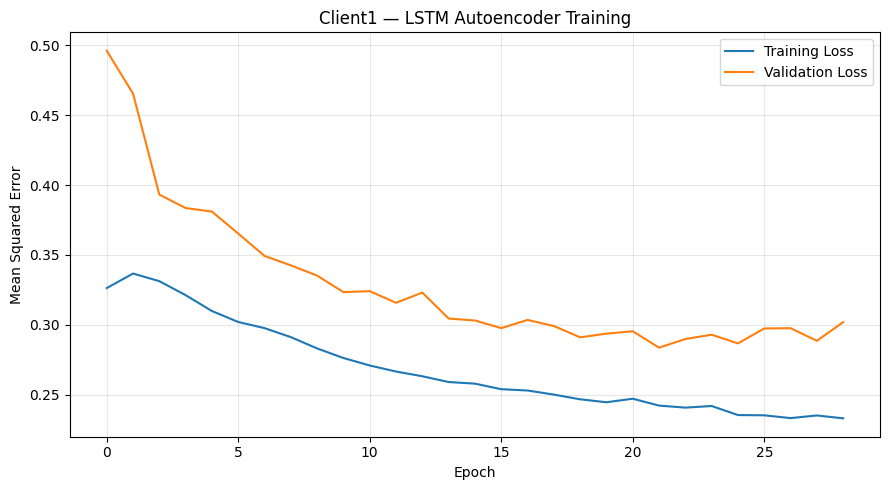


TRAINING MODEL: Client2

Training shape: (115881, 30, 7)
Validation shape: (24823, 30, 7)
Number of features: 7


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 7)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 7)          │           455 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,455 (251.78 KB)

 Trainable params: 64,455 (251.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 54s 14ms/step - loss: 0.4606 - val_loss: 0.3898
Epoch 2/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 13ms/step - loss: 0.4851 - val_loss: 0.3738
Epoch 3/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 13ms/step - loss: 0.4771 - val_loss: 0.3337
Epoch 4/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.4829 - val_loss: 0.3192
Epoch 5/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.4751 - val_loss: 0.3230
Epoch 6/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 14ms/step - loss: 0.4771 - val_loss: 0.3309
Epoch 7/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 13ms/step - loss: 0.4831 - val_loss: 0.3446
Epoch 8/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 14ms/step - loss: 0.4776 - val_loss: 0.3303
Epoch 9/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.4716 - val_loss: 0.2843
Epoch 10/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.4667 - val_loss: 0.3258
Epoch 11/50
3622/3622 ━━━━━━━━━━━━━━━━━━━━ 49s 14ms/step - loss: 0.4661 - val_loss: 0.2776
Epoch 12

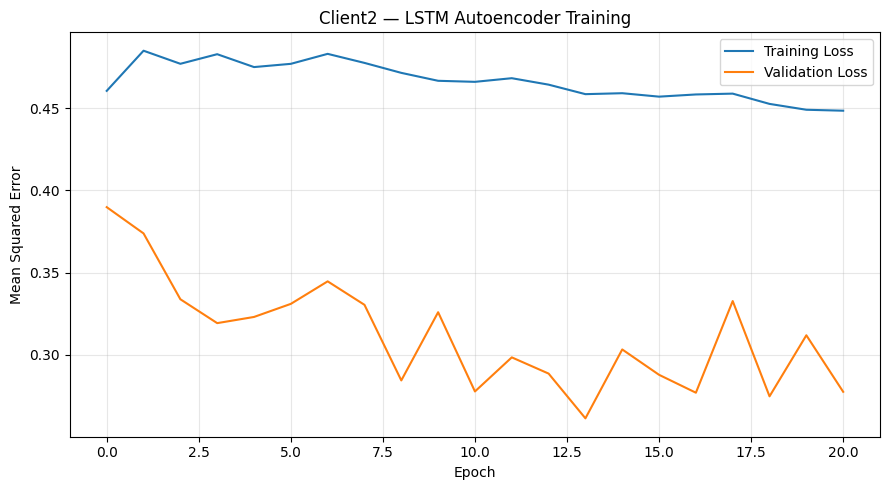


TRAINING MODEL: Client3

Training shape: (115740, 30, 7)
Validation shape: (24791, 30, 7)
Number of features: 7


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 7)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 7)          │           455 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 64,455 (251.78 KB)

 Trainable params: 64,455 (251.78 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 50s 13ms/step - loss: 0.5096 - val_loss: 0.4676
Epoch 2/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 51s 14ms/step - loss: 0.5101 - val_loss: 0.4850
Epoch 3/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 47s 13ms/step - loss: 0.5307 - val_loss: 0.4608
Epoch 4/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 49s 13ms/step - loss: 0.5109 - val_loss: 0.4613
Epoch 5/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.5046 - val_loss: 0.4619
Epoch 6/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.5105 - val_loss: 0.4587
Epoch 7/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.4910 - val_loss: 0.4888
Epoch 8/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.5089 - val_loss: 0.4516
Epoch 9/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.4937 - val_loss: 0.5201
Epoch 10/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 49s 14ms/step - loss: 0.4986 - val_loss: 0.5534
Epoch 11/50
3617/3617 ━━━━━━━━━━━━━━━━━━━━ 48s 13ms/step - loss: 0.4952 - val_loss: 0.5041
Epoch 12

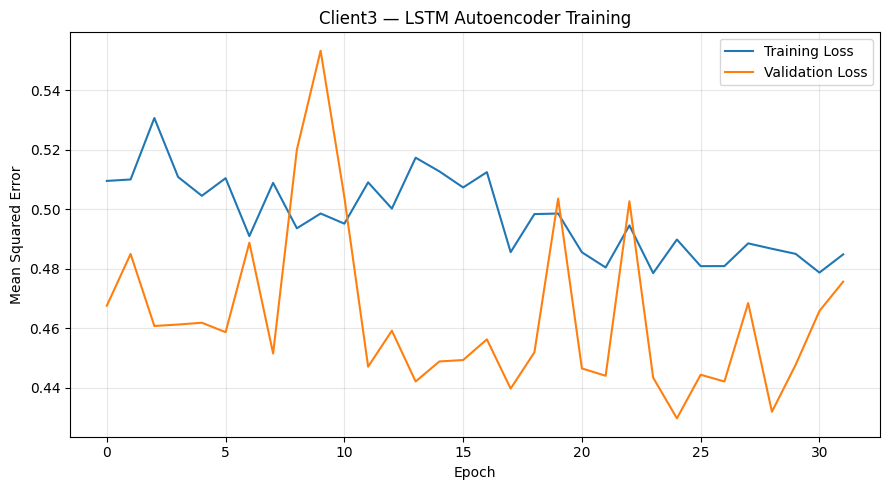


TRAINING MODEL: Switch

Training shape: (103187, 30, 4)
Validation shape: (22102, 30, 4)
Number of features: 4


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 30, 4)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 30, 64)         │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 30, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 30, 32)         │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 30, 4)          │           260 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 63,492 (248.02 KB)

 Trainable params: 63,492 (248.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 49s 14ms/step - loss: 0.4169 - val_loss: 0.5311
Epoch 2/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 44s 14ms/step - loss: 0.4505 - val_loss: 0.6187
Epoch 3/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 44s 14ms/step - loss: 0.4206 - val_loss: 0.5680
Epoch 4/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 44s 14ms/step - loss: 0.3826 - val_loss: 0.5004
Epoch 5/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 44s 14ms/step - loss: 0.3632 - val_loss: 0.3995
Epoch 6/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 44s 14ms/step - loss: 0.3538 - val_loss: 0.3972
Epoch 7/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 43s 13ms/step - loss: 0.3523 - val_loss: 0.4051
Epoch 8/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 42s 13ms/step - loss: 0.3496 - val_loss: 0.4188
Epoch 9/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 42s 13ms/step - loss: 0.3491 - val_loss: 0.4004
Epoch 10/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 43s 13ms/step - loss: 0.3254 - val_loss: 0.4362
Epoch 11/50
3225/3225 ━━━━━━━━━━━━━━━━━━━━ 43s 13ms/step - loss: 0.3188 - val_loss: 0.3953
Epoch 12

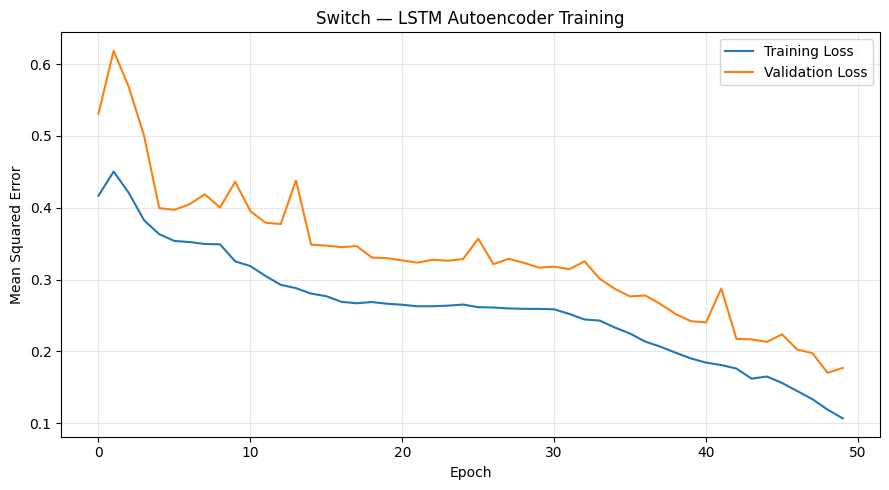


SECTION 5 COMPLETE

Training Summary:
 Device  Epochs_Completed  Best_Epoch  Final_Training_Loss  Best_Validation_Loss  Features  Sequences
Client1                29          22             0.233239              0.283748         7     115901
Client2                21          14             0.448533              0.261245         7     115881
Client3                32          25             0.484886              0.429742         7     115740
 Switch                50          49             0.106824              0.170183         4     103187

All models saved to: LSTM_Results\Models
Training summary saved to: LSTM_Results\Training_Summary.csv


In [6]:
# ============================================================
# SECTION 5 — BUILD AND TRAIN LSTM AUTOENCODER
# ============================================================

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, LSTM, RepeatVector, TimeDistributed, Dense
)
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import backend as K

import gc

# ------------------------------------------------------------
# 5.1 Build the LSTM Autoencoder
# ------------------------------------------------------------

def build_lstm_autoencoder(sequence_length, n_features):
    """
    Build an LSTM Autoencoder.

    Input:
        (30, 7) for Raspberry Pis
        (30, 4) for Switch

    Output:
        Reconstructed sequence with the same shape.
    """

    inputs = Input(
        shape=(sequence_length, n_features)
    )

    # Encoder
    x = LSTM(
        64,
        activation="tanh",
        return_sequences=True
    )(inputs)

    x = LSTM(
        32,
        activation="tanh",
        return_sequences=False
    )(x)

    # Repeat encoded representation
    x = RepeatVector(sequence_length)(x)

    # Decoder
    x = LSTM(
        32,
        activation="tanh",
        return_sequences=True
    )(x)

    x = LSTM(
        64,
        activation="tanh",
        return_sequences=True
    )(x)

    # Reconstruct original features
    outputs = TimeDistributed(
        Dense(n_features)
    )(x)

    model = Model(inputs, outputs)

    # Compile model
    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="mse"
    )

    return model


# ------------------------------------------------------------
# 5.2 Prepare model storage
# ------------------------------------------------------------

models = {}
training_history = {}
training_summary = []

MODEL_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 5.3 Train each device independently
# ------------------------------------------------------------

for device, data in sequence_data.items():

    print("\n" + "=" * 60)
    print(f"TRAINING MODEL: {device}")
    print("=" * 60)

    # Clear previous TensorFlow graphs
    K.clear_session()

    # Retrieve sequences
    X_train = data["train"]
    X_val = data["val"]

    # Automatically detect input dimensions
    sequence_length = X_train.shape[1]
    n_features = X_train.shape[2]

    print("\nTraining shape:", X_train.shape)
    print("Validation shape:", X_val.shape)
    print("Number of features:", n_features)

    # --------------------------------------------------------
    # Build model
    # --------------------------------------------------------

    model = build_lstm_autoencoder(
        sequence_length=sequence_length,
        n_features=n_features
    )

    model.summary()

    # --------------------------------------------------------
    # Early stopping
    # --------------------------------------------------------

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True,
        verbose=1
    )

    # --------------------------------------------------------
    # Train model
    # --------------------------------------------------------

    history = model.fit(
        X_train,
        X_train,

        validation_data=(X_val, X_val),

        epochs=EPOCHS,
        batch_size=BATCH_SIZE,

        callbacks=[early_stopping],

        shuffle=False,
        verbose=1
    )

    # --------------------------------------------------------
    # Save trained model
    # --------------------------------------------------------

    model_path = MODEL_DIR / f"{device}_LSTM_Autoencoder.keras"

    model.save(model_path)

    models[device] = model

    training_history[device] = history.history

    # --------------------------------------------------------
    # Record training results
    # --------------------------------------------------------

    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    best_val_loss = float(
        np.min(history.history["val_loss"])
    )

    final_train_loss = float(
        history.history["loss"][-1]
    )

    training_summary.append({
        "Device": device,
        "Epochs_Completed": len(history.history["loss"]),
        "Best_Epoch": best_epoch,
        "Final_Training_Loss": final_train_loss,
        "Best_Validation_Loss": best_val_loss,
        "Features": n_features,
        "Sequences": len(X_train)
    })

    print("\nTraining Results:")
    print("Epochs completed:", len(history.history["loss"]))
    print("Best epoch:", best_epoch)
    print("Final training loss:", round(final_train_loss, 6))
    print("Best validation loss:", round(best_val_loss, 6))

    print("\nModel saved:", model_path)

    # --------------------------------------------------------
    # Plot training history
    # --------------------------------------------------------

    plt.figure(figsize=(9, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{device} — LSTM Autoencoder Training")
    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    plot_path = PLOTS_DIR / f"{device}_Training_Loss.png"

    plt.savefig(plot_path, dpi=150)
    plt.show()
    plt.close()

    # Release temporary training objects
    del history, X_train, X_val
    gc.collect()


# ============================================================
# 5.4 FINAL TRAINING SUMMARY
# ============================================================

training_summary_df = pd.DataFrame(training_summary)

summary_path = OUTPUT_DIR / "Training_Summary.csv"

training_summary_df.to_csv(
    summary_path,
    index=False
)

print("\n" + "=" * 60)
print("SECTION 5 COMPLETE")
print("=" * 60)

print("\nTraining Summary:")
print(training_summary_df.to_string(index=False))

print("\nAll models saved to:", MODEL_DIR)
print("Training summary saved to:", summary_path)

6 - Split and scale data


DEVICE: Client1

Anomaly threshold: 1.626298

Test Results:
Total sequences: 24827
Anomalous sequences: 330
Anomaly rate: 1.33%

Reconstruction Error:
Mean: 0.506671
Maximum: 2.190834


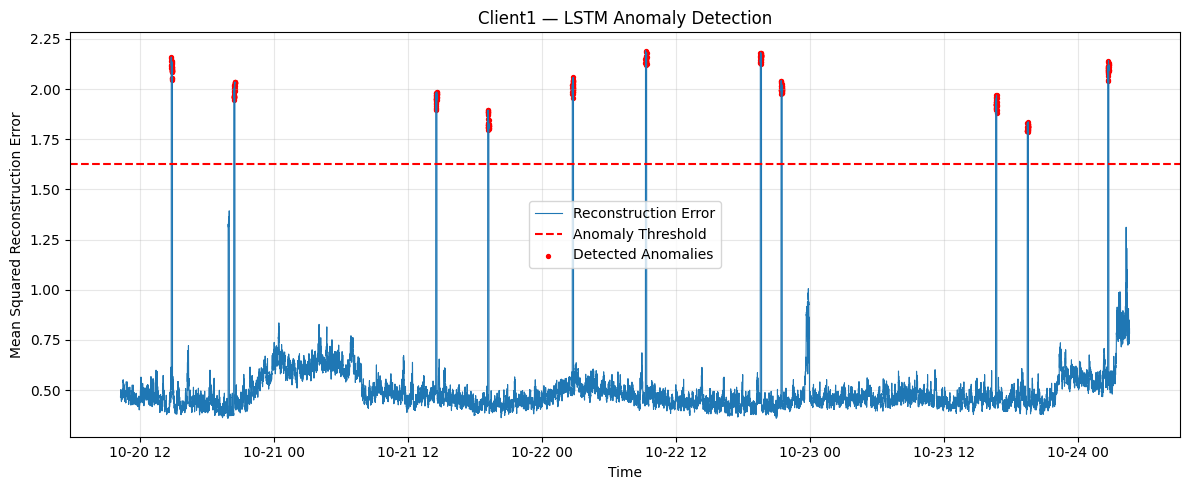


Results saved: LSTM_Results\Anomaly_Results\Client1_Anomaly_Results.csv

DEVICE: Client2

Anomaly threshold: 1.437925

Test Results:
Total sequences: 24824
Anomalous sequences: 826
Anomaly rate: 3.33%

Reconstruction Error:
Mean: 0.540374
Maximum: 4.212047


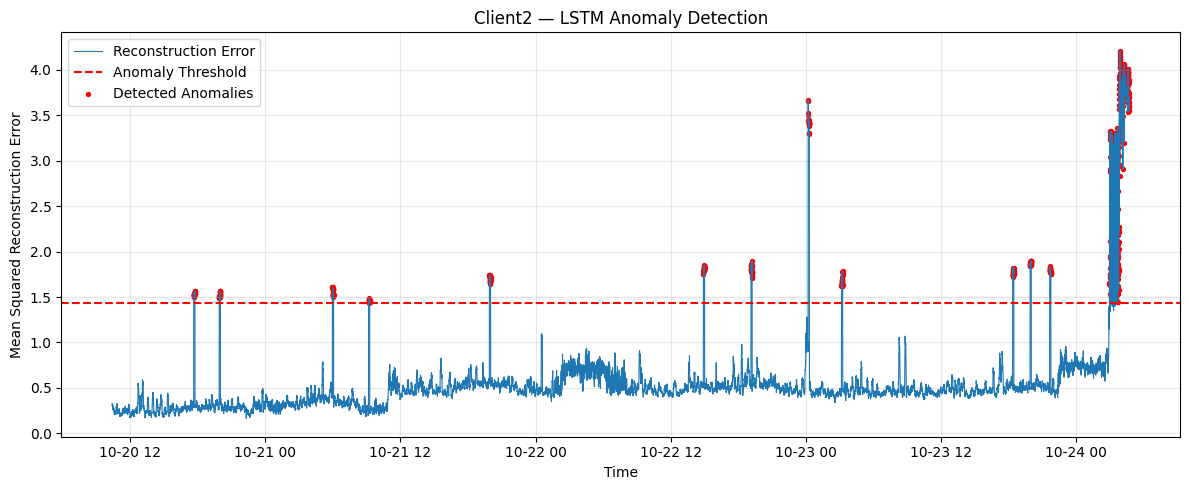


Results saved: LSTM_Results\Anomaly_Results\Client2_Anomaly_Results.csv

DEVICE: Client3

Anomaly threshold: 2.994029

Test Results:
Total sequences: 24791
Anomalous sequences: 257
Anomaly rate: 1.04%

Reconstruction Error:
Mean: 0.778665
Maximum: 3.912889


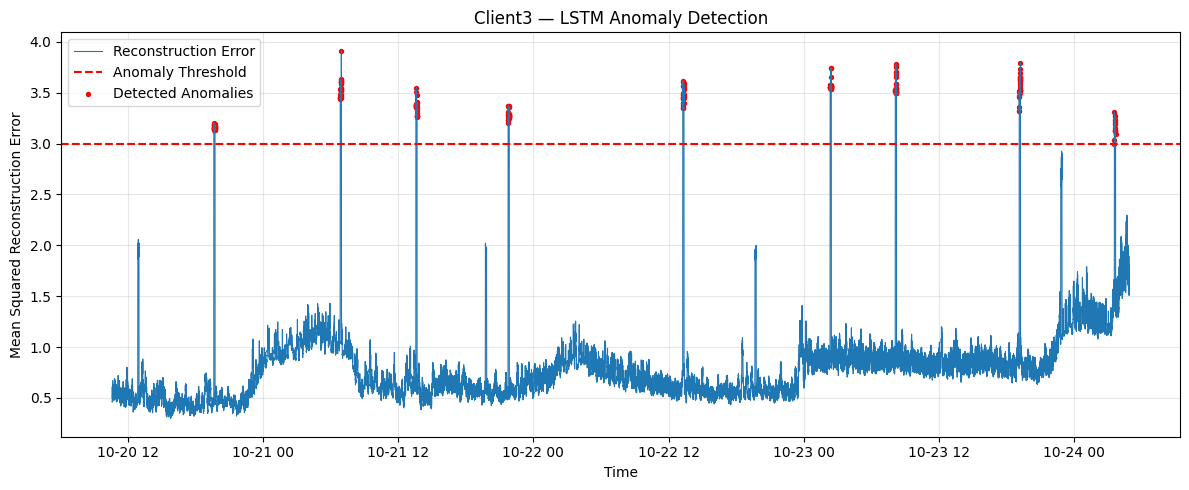


Results saved: LSTM_Results\Anomaly_Results\Client3_Anomaly_Results.csv

DEVICE: Switch

Anomaly threshold: 0.624612

Test Results:
Total sequences: 22045
Anomalous sequences: 327
Anomaly rate: 1.48%

Reconstruction Error:
Mean: 0.175652
Maximum: 1.465546


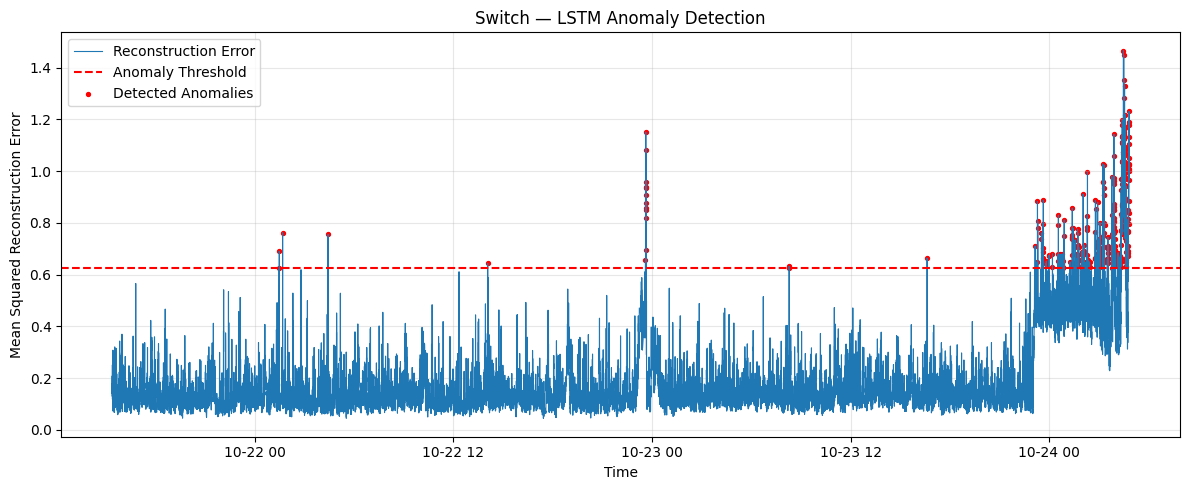


Results saved: LSTM_Results\Anomaly_Results\Switch_Anomaly_Results.csv

SECTION 6 COMPLETE

Anomaly Detection Summary:
 Device  Test_Sequences  Anomalous_Sequences  Anomaly_Rate_Percent  Threshold  Mean_Test_Error  Max_Test_Error
Client1           24827                  330              1.329198   1.626298         0.506671        2.190834
Client2           24824                  826              3.327425   1.437925         0.540374        4.212047
Client3           24791                  257              1.036667   2.994029         0.778665        3.912889
 Switch           22045                  327              1.483330   0.624612         0.175652        1.465546

Results saved to: LSTM_Results\Anomaly_Results
Plots saved to: LSTM_Results\Plots


In [7]:
# ============================================================
# SECTION 6 — ANOMALY DETECTION AND EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow.keras.models import load_model

# ------------------------------------------------------------
# 6.1 Configuration
# ------------------------------------------------------------

ANOMALY_PERCENTILE = 99
PREDICTION_BATCH_SIZE = 256

# Store results
anomaly_results = {}
anomaly_summary = []
anomaly_thresholds = {}

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 6.2 Calculate reconstruction errors
# ------------------------------------------------------------

def calculate_reconstruction_errors(model, X):
    """
    Reconstruct LSTM sequences and calculate:

    1. Total MSE for each sequence
    2. MSE for each original metric

    Returns:
        sequence_errors: (number of sequences,)
        feature_errors:  (number of sequences, metrics)
    """

    # Allocate output arrays
    sequence_errors = np.empty(
        len(X), dtype=np.float64
    )

    feature_errors = np.empty(
        (len(X), X.shape[2]), dtype=np.float64
    )

    # Predict in batches to reduce memory usage
    for start in range(0, len(X), PREDICTION_BATCH_SIZE):

        end = min(start + PREDICTION_BATCH_SIZE, len(X))

        batch = X[start:end]

        reconstructed = model.predict(
            batch,
            batch_size=PREDICTION_BATCH_SIZE,
            verbose=0
        )

        # Squared reconstruction error
        squared_error = (
            batch.astype(np.float64)
            - reconstructed.astype(np.float64)
        ) ** 2

        # Average error across time and metrics
        sequence_errors[start:end] = squared_error.mean(
            axis=(1, 2)
        )

        # Average error across time for each metric
        feature_errors[start:end] = squared_error.mean(
            axis=1
        )

    return sequence_errors, feature_errors


# ------------------------------------------------------------
# 6.3 Process each device
# ------------------------------------------------------------

for device, data in sequence_data.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    # Load trained model if not already in memory
    if device in models:
        model = models[device]
    else:
        model_path = (
            MODEL_DIR / f"{device}_LSTM_Autoencoder.keras"
        )
        model = load_model(model_path)

    X_val = data["val"]
    X_test = data["test"]

    metrics = data["metrics"]

    # --------------------------------------------------------
    # Calculate validation reconstruction error
    # --------------------------------------------------------

    val_errors, _ = calculate_reconstruction_errors(
        model, X_val
    )

    # Determine anomaly threshold from validation only
    threshold = float(
        np.percentile(val_errors, ANOMALY_PERCENTILE)
    )

    anomaly_thresholds[device] = threshold

    print("\nAnomaly threshold:", round(threshold, 6))

    # --------------------------------------------------------
    # Calculate test reconstruction error
    # --------------------------------------------------------

    test_errors, feature_errors = (
        calculate_reconstruction_errors(model, X_test)
    )

    # Identify anomalous sequences
    is_anomaly = test_errors > threshold

    # Metric contributing most to reconstruction error
    highest_feature_index = np.argmax(
        feature_errors, axis=1
    )

    most_unusual_metric = [
        metrics[i] for i in highest_feature_index
    ]

    # --------------------------------------------------------
    # Create timestamped anomaly results
    # --------------------------------------------------------

    results = pd.DataFrame({
        "timestamp": data["test_timestamps"],
        "reconstruction_error": test_errors,
        "threshold": threshold,
        "is_anomaly": is_anomaly,
        "most_unusual_metric": most_unusual_metric
    })

    # Add individual metric reconstruction errors
    for i, metric in enumerate(metrics):
        results[f"{metric}_error"] = feature_errors[:, i]

    # Store results
    anomaly_results[device] = results

    # Save results to CSV
    output_file = (
        RESULTS_DIR / f"{device}_Anomaly_Results.csv"
    )

    results.to_csv(output_file, index=False)

    # --------------------------------------------------------
    # Calculate anomaly statistics
    # --------------------------------------------------------

    total_sequences = len(results)

    anomalous_sequences = int(is_anomaly.sum())

    anomaly_rate = (
        100 * anomalous_sequences / total_sequences
    )

    # Save summary
    anomaly_summary.append({
        "Device": device,
        "Test_Sequences": total_sequences,
        "Anomalous_Sequences": anomalous_sequences,
        "Anomaly_Rate_Percent": anomaly_rate,
        "Threshold": threshold,
        "Mean_Test_Error": float(np.mean(test_errors)),
        "Max_Test_Error": float(np.max(test_errors))
    })

    print("\nTest Results:")
    print("Total sequences:", total_sequences)
    print("Anomalous sequences:", anomalous_sequences)
    print(f"Anomaly rate: {anomaly_rate:.2f}%")

    print("\nReconstruction Error:")
    print("Mean:", round(np.mean(test_errors), 6))
    print("Maximum:", round(np.max(test_errors), 6))

    # --------------------------------------------------------
    # Plot reconstruction error
    # --------------------------------------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        results["timestamp"],
        results["reconstruction_error"],
        label="Reconstruction Error",
        linewidth=0.8
    )

    plt.axhline(
        threshold,
        color="red",
        linestyle="--",
        label="Anomaly Threshold"
    )

    plt.scatter(
        results.loc[is_anomaly, "timestamp"],
        results.loc[is_anomaly, "reconstruction_error"],
        color="red",
        s=8,
        label="Detected Anomalies"
    )

    plt.title(f"{device} — LSTM Anomaly Detection")
    plt.xlabel("Time")
    plt.ylabel("Mean Squared Reconstruction Error")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    plot_path = (
        PLOTS_DIR / f"{device}_Anomaly_Detection.png"
    )

    plt.savefig(plot_path, dpi=150)
    plt.show()
    plt.close()

    print("\nResults saved:", output_file)


# ============================================================
# 6.4 FINAL ANOMALY SUMMARY
# ============================================================

anomaly_summary_df = pd.DataFrame(anomaly_summary)

summary_path = OUTPUT_DIR / "Anomaly_Summary.csv"

anomaly_summary_df.to_csv(
    summary_path,
    index=False
)

# Save device thresholds
import joblib

joblib.dump(
    anomaly_thresholds,
    MODEL_DIR / "Anomaly_Thresholds.joblib"
)

print("\n" + "=" * 60)
print("SECTION 6 COMPLETE")
print("=" * 60)

print("\nAnomaly Detection Summary:")
print(anomaly_summary_df.to_string(index=False))

print("\nResults saved to:", RESULTS_DIR)
print("Plots saved to:", PLOTS_DIR)

7 - Build LSTM Autoencoder


DEVICE: Client1

Total anomalous sequences: 330
Distinct anomaly events: 11

Event Summary:
 Event_ID                       Start_Time                         End_Time  Duration_Minutes  Anomalous_Sequences  Peak_Error  Peak_Severity_Ratio Dominant_Metric
        1 2026-10-20 14:49:06.325889+00:00 2026-10-20 14:55:26.244263+00:00          6.331973                   30    2.159061             1.327593         cpu_pct
        2 2026-10-20 20:24:42.814760+00:00 2026-10-20 20:31:02.686883+00:00          6.331202                   30    2.035008             1.251313         cpu_pct
        3 2026-10-21 14:30:23.583286+00:00 2026-10-21 14:36:43.486423+00:00          6.331719                   30    1.984792             1.220436         cpu_pct
        4 2026-10-21 19:09:26.226833+00:00 2026-10-21 19:15:46.078747+00:00          6.330865                   30    1.895531             1.165550         cpu_pct
        5 2026-10-22 02:44:16.190525+00:00 2026-10-22 02:50:36.361269+00:00          6.

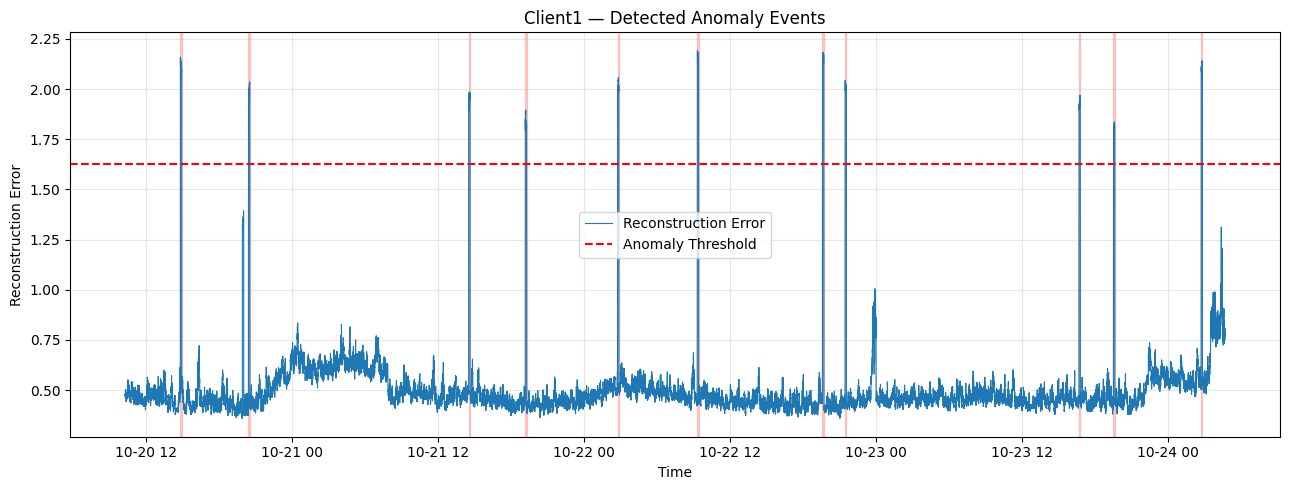


Saved: LSTM_Results\Anomaly_Events\Client1_Events.csv

DEVICE: Client2

Total anomalous sequences: 826
Distinct anomaly events: 18

Event Summary:
 Event_ID                       Start_Time                         End_Time  Duration_Minutes  Anomalous_Sequences  Peak_Error  Peak_Severity_Ratio Dominant_Metric
        1 2026-10-20 17:37:48.096361+00:00 2026-10-20 17:44:08.000643+00:00          6.331738                   30    1.565242             1.088542         cpu_pct
        2 2026-10-20 19:53:36.768535+00:00 2026-10-20 19:59:56.672341+00:00          6.331730                   30    1.567047             1.089798         cpu_pct
        3 2026-10-21 05:56:56.992351+00:00 2026-10-21 06:03:16.928159+00:00          6.332263                   30    1.615941             1.123801         cpu_pct
        4 2026-10-21 09:09:45.097908+00:00 2026-10-21 09:16:04.960477+00:00          6.331043                   28    1.491153             1.037017         cpu_pct
        5 2026-10-21 19:54:10.68

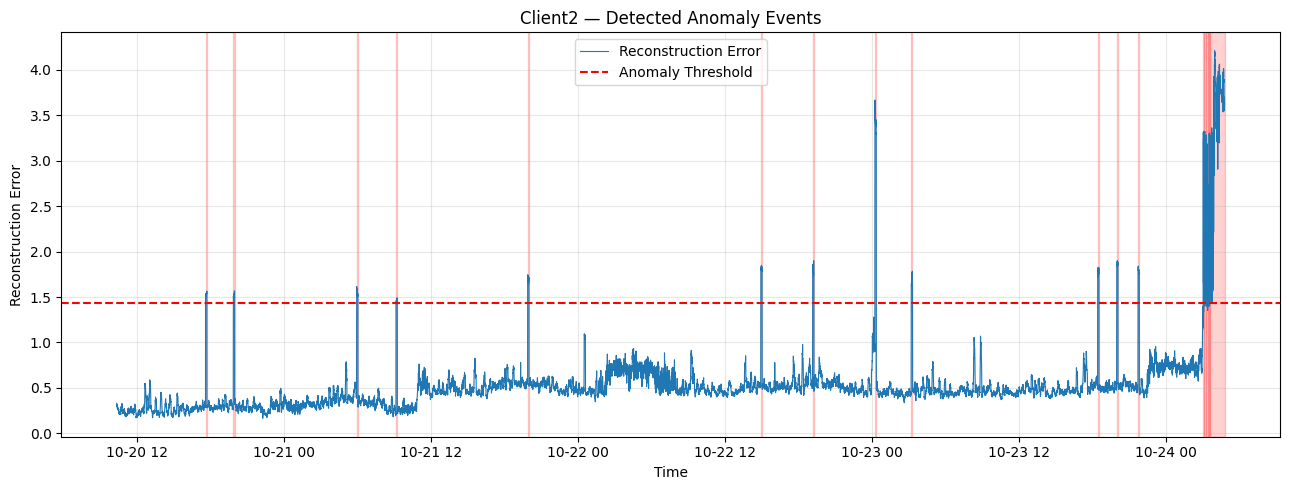


Saved: LSTM_Results\Anomaly_Events\Client2_Events.csv

DEVICE: Client3

Total anomalous sequences: 257
Distinct anomaly events: 15

Event Summary:
 Event_ID                       Start_Time                         End_Time  Duration_Minutes  Anomalous_Sequences  Peak_Error  Peak_Severity_Ratio Dominant_Metric
        1 2026-10-20 19:38:25.411188+00:00 2026-10-20 19:44:45.403788+00:00          6.333210                   30    3.205439             1.070611         cpu_pct
        2 2026-10-21 06:51:25.281314+00:00 2026-10-21 06:57:45.243550+00:00          6.332704                   30    3.912889             1.306898         cpu_pct
        3 2026-10-21 13:34:24.689184+00:00 2026-10-21 13:40:44.768914+00:00          6.334662                   30    3.550666             1.185916         cpu_pct
        4 2026-10-21 21:45:23.243634+00:00 2026-10-21 21:51:43.243505+00:00          6.333331                   30    3.373106             1.126611         cpu_pct
        5 2026-10-22 13:15:49.73

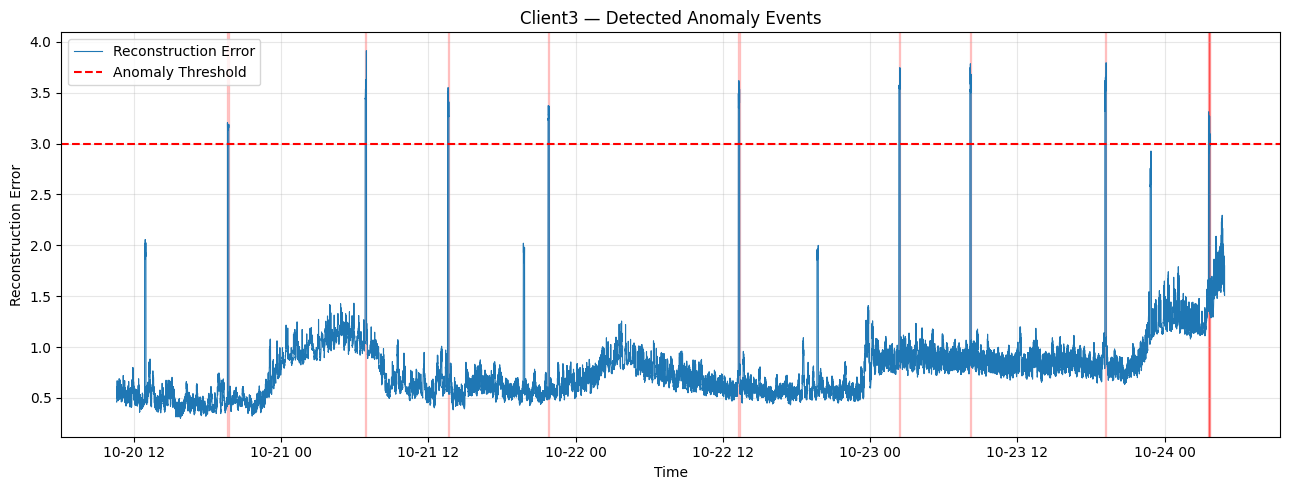


Saved: LSTM_Results\Anomaly_Events\Client3_Events.csv

DEVICE: Switch

Total anomalous sequences: 327
Distinct anomaly events: 95

Event Summary:
 Event_ID                Start_Time                  End_Time  Duration_Minutes  Anomalous_Sequences  Peak_Error  Peak_Severity_Ratio Dominant_Metric
        1 2026-10-22 01:29:50+00:00 2026-10-22 01:30:00+00:00          0.166667                    2    0.690590             1.105631         cpu_pct
        2 2026-10-22 01:41:50+00:00 2026-10-22 01:41:50+00:00          0.000000                    1    0.761939             1.219861         cpu_pct
        3 2026-10-22 04:26:30+00:00 2026-10-22 04:26:30+00:00          0.000000                    1    0.755556             1.209642         cpu_pct
        4 2026-10-22 14:04:50+00:00 2026-10-22 14:04:50+00:00          0.000000                    1    0.643892             1.030867         cpu_pct
        5 2026-10-22 23:36:30+00:00 2026-10-22 23:36:30+00:00          0.000000                    1   

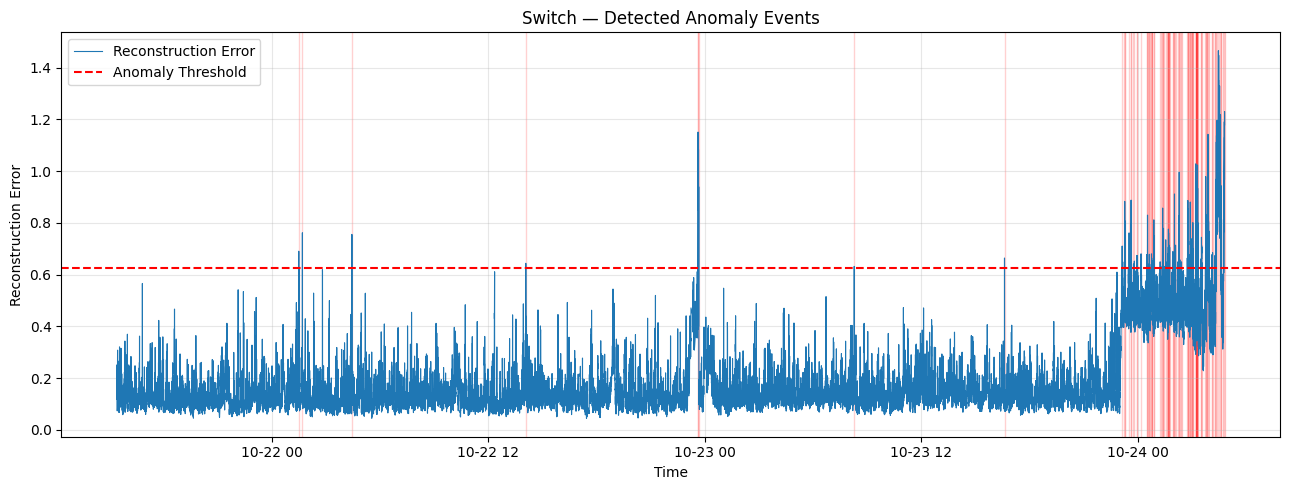


Saved: LSTM_Results\Anomaly_Events\Switch_Events.csv

SECTION 7 COMPLETE

Final Event Summary:
 Device  Total_Events  Anomalous_Sequences  Longest_Event_Minutes  Highest_Severity_Ratio
Client1            11                  330               6.336179                1.347130
Client2            18                  826              73.157709                2.929255
Client3            15                  257               6.334662                1.306898
 Switch            95                  327              17.166667                2.346332


In [8]:
# ============================================================
# SECTION 7 — ANOMALY EVENT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 7.1 Configuration
# ------------------------------------------------------------

# Maximum gap between consecutive anomalous sequence
# timestamps for grouping them into the same event.
EVENT_GAP_SECONDS = {
    "Client1": 30,
    "Client2": 30,
    "Client3": 30,
    "Switch": 20
}

EVENT_DIR = OUTPUT_DIR / "Anomaly_Events"
EVENT_DIR.mkdir(parents=True, exist_ok=True)

event_results = {}
event_summary = []

# ------------------------------------------------------------
# 7.2 Function to group anomalous sequences
# ------------------------------------------------------------

def identify_anomaly_events(results, device, metrics, max_gap):
    """
    Groups consecutive anomalous sequence timestamps into events.

    Returns:
        events: DataFrame containing individual anomaly events
        labelled_results: Original results with event IDs
    """

    df = results.copy()

    df["timestamp"] = pd.to_datetime(
        df["timestamp"], utc=True
    )

    df = df.sort_values("timestamp").reset_index(drop=True)

    # Default: no event assigned
    df["event_id"] = pd.NA

    # Select anomalous sequences only
    anomalies = df[df["is_anomaly"]].copy()

    if anomalies.empty:
        return pd.DataFrame(), df

    # Time between anomalous sequence timestamps
    gaps = anomalies["timestamp"].diff().dt.total_seconds()

    # Start a new event after a large gap
    new_event = gaps.isna() | (gaps > max_gap)

    anomalies["event_id"] = new_event.cumsum().astype(int)

    # Copy event IDs into the full results
    df.loc[anomalies.index, "event_id"] = anomalies["event_id"]

    events = []

    # --------------------------------------------------------
    # 7.3 Summarise individual events
    # --------------------------------------------------------

    for event_id, group in anomalies.groupby("event_id"):

        first_time = group["timestamp"].min()
        last_time = group["timestamp"].max()

        # Duration covered by anomalous sequence end times
        duration_minutes = (
            (last_time - first_time).total_seconds() / 60
        )

        peak_error = group["reconstruction_error"].max()

        threshold = group["threshold"].iloc[0]

        severity_ratio = (
            peak_error / threshold
            if threshold > 0 else np.nan
        )

        # Calculate average reconstruction error for each metric
        metric_errors = {}

        for metric in metrics:
            column = f"{metric}_error"

            if column in group.columns:
                metric_errors[metric] = group[column].mean()

        dominant_metric = (
            max(metric_errors, key=metric_errors.get)
            if metric_errors else "Unknown"
        )

        events.append({
            "Device": device,
            "Event_ID": int(event_id),
            "Start_Time": first_time,
            "End_Time": last_time,
            "Duration_Minutes": duration_minutes,
            "Anomalous_Sequences": len(group),
            "Peak_Error": peak_error,
            "Threshold": threshold,
            "Peak_Severity_Ratio": severity_ratio,
            "Dominant_Metric": dominant_metric
        })

    return pd.DataFrame(events), df


# ------------------------------------------------------------
# 7.4 Analyse each device
# ------------------------------------------------------------

for device, results in anomaly_results.items():

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    metrics = sequence_data[device]["metrics"]

    events, labelled_results = identify_anomaly_events(
        results=results,
        device=device,
        metrics=metrics,
        max_gap=EVENT_GAP_SECONDS[device]
    )

    event_results[device] = events

    # Save event table
    events_file = EVENT_DIR / f"{device}_Events.csv"
    events.to_csv(events_file, index=False)

    # Save sequence results with event IDs
    labelled_file = EVENT_DIR / f"{device}_Labelled_Anomalies.csv"
    labelled_results.to_csv(labelled_file, index=False)

    print("\nTotal anomalous sequences:",
          int(results["is_anomaly"].sum()))

    print("Distinct anomaly events:", len(events))

    if not events.empty:

        print("\nEvent Summary:")
        print(
            events[
                [
                    "Event_ID",
                    "Start_Time",
                    "End_Time",
                    "Duration_Minutes",
                    "Anomalous_Sequences",
                    "Peak_Error",
                    "Peak_Severity_Ratio",
                    "Dominant_Metric"
                ]
            ].to_string(index=False)
        )

        # Store summary
        event_summary.append({
            "Device": device,
            "Total_Events": len(events),
            "Anomalous_Sequences": int(
                results["is_anomaly"].sum()
            ),
            "Longest_Event_Minutes": events[
                "Duration_Minutes"
            ].max(),
            "Highest_Severity_Ratio": events[
                "Peak_Severity_Ratio"
            ].max()
        })

    else:

        event_summary.append({
            "Device": device,
            "Total_Events": 0,
            "Anomalous_Sequences": 0,
            "Longest_Event_Minutes": 0,
            "Highest_Severity_Ratio": 0
        })

    # --------------------------------------------------------
    # 7.5 Plot anomaly events
    # --------------------------------------------------------

    plt.figure(figsize=(13, 5))

    plt.plot(
        labelled_results["timestamp"],
        labelled_results["reconstruction_error"],
        linewidth=0.8,
        label="Reconstruction Error"
    )

    if not events.empty:

        for _, event in events.iterrows():

            plt.axvspan(
                event["Start_Time"],
                event["End_Time"],
                color="red",
                alpha=0.18
            )

    plt.axhline(
        labelled_results["threshold"].iloc[0],
        color="red",
        linestyle="--",
        label="Anomaly Threshold"
    )

    plt.title(f"{device} — Detected Anomaly Events")
    plt.xlabel("Time")
    plt.ylabel("Reconstruction Error")
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()

    plot_file = PLOTS_DIR / f"{device}_Anomaly_Events.png"

    plt.savefig(plot_file, dpi=150)
    plt.show()
    plt.close()

    print("\nSaved:", events_file)


# ============================================================
# 7.6 FINAL SUMMARY
# ============================================================

event_summary_df = pd.DataFrame(event_summary)

event_summary_df.to_csv(
    OUTPUT_DIR / "Event_Summary.csv",
    index=False
)

print("\n" + "=" * 60)
print("SECTION 7 COMPLETE")
print("=" * 60)

print("\nFinal Event Summary:")
print(event_summary_df.to_string(index=False))

8 - 

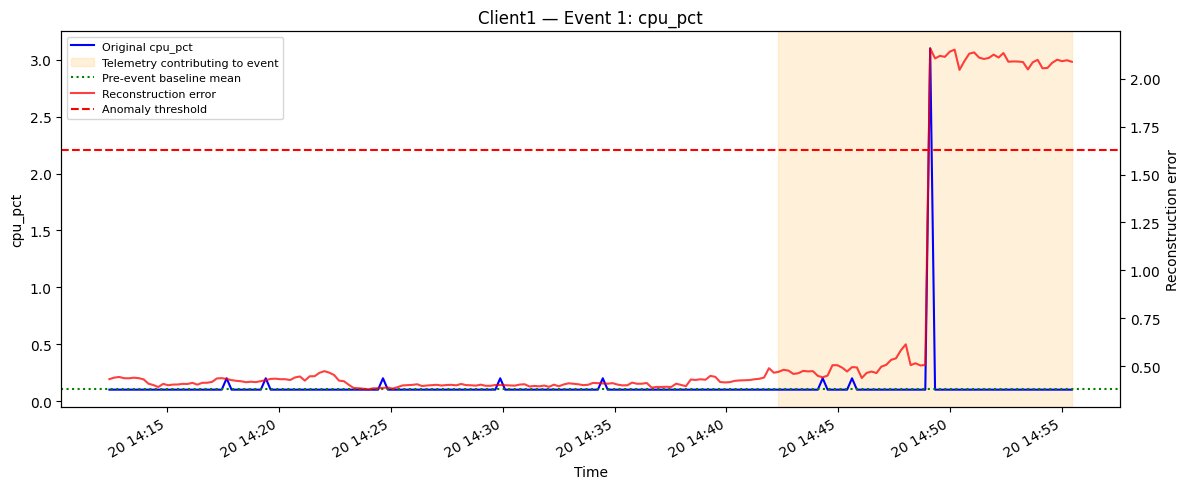

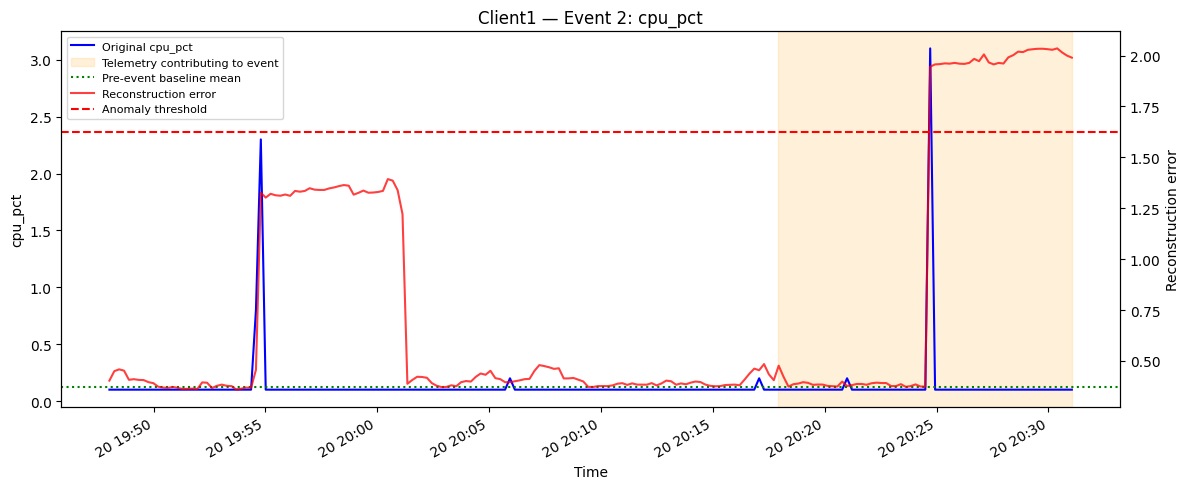

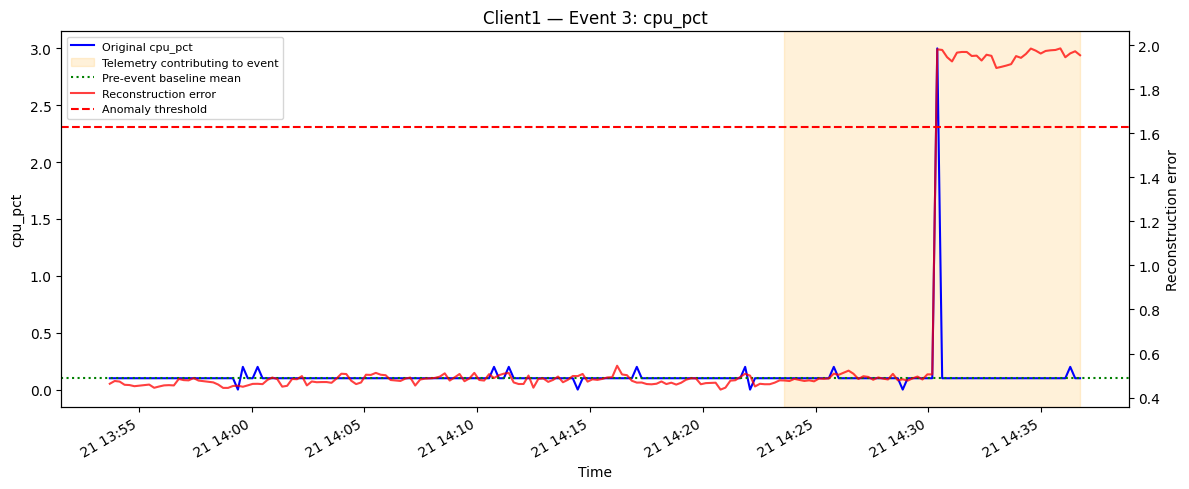

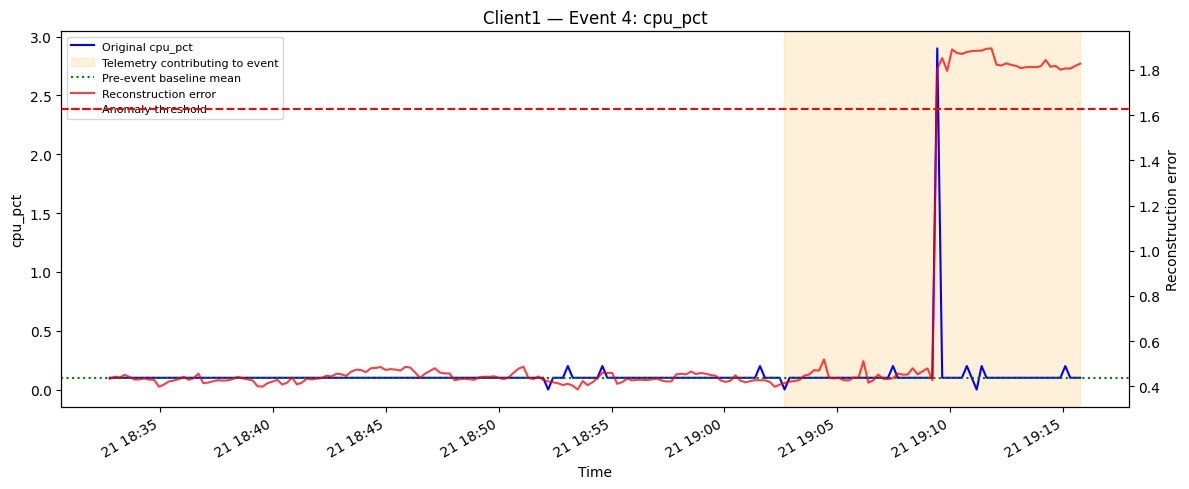

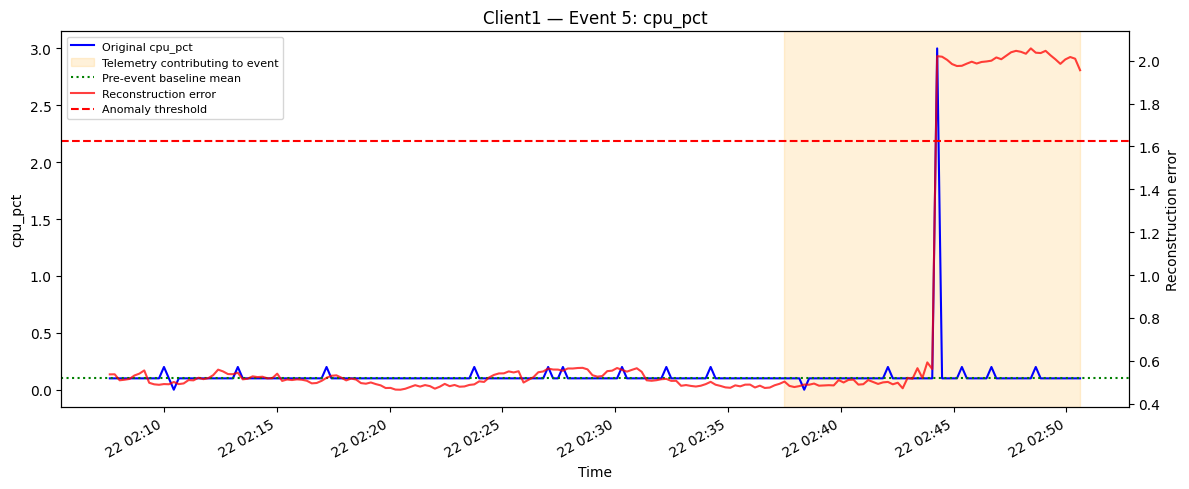

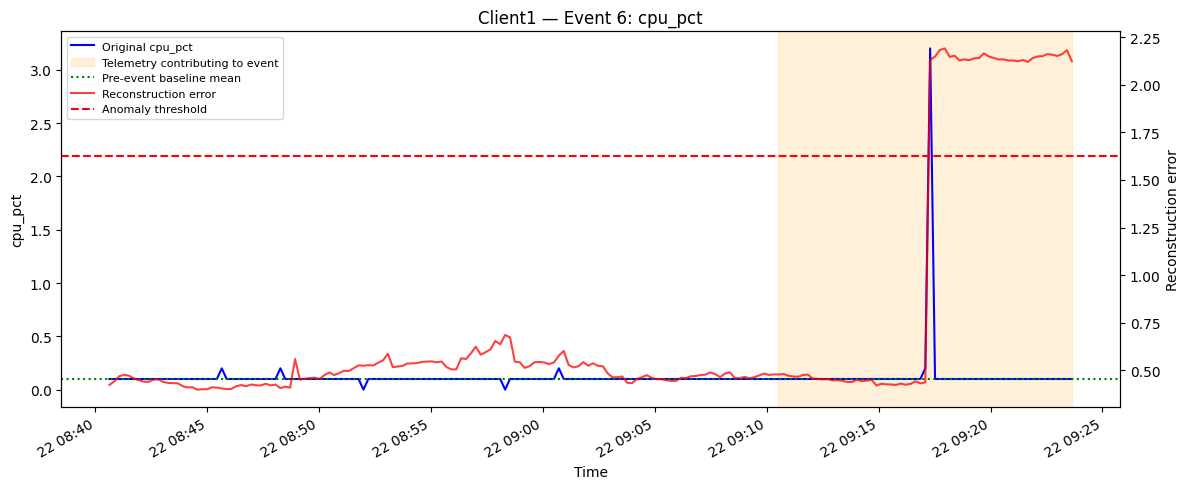

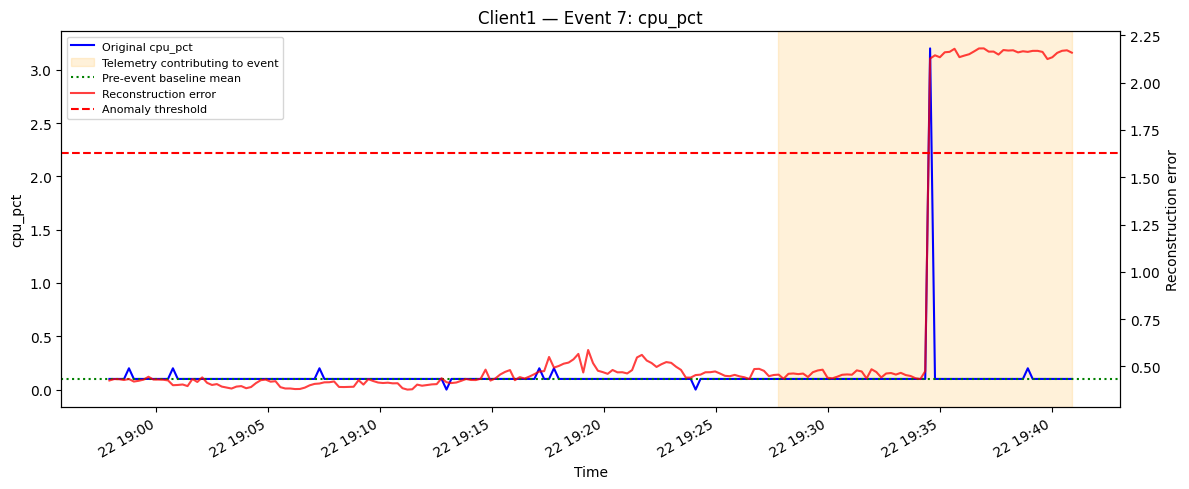

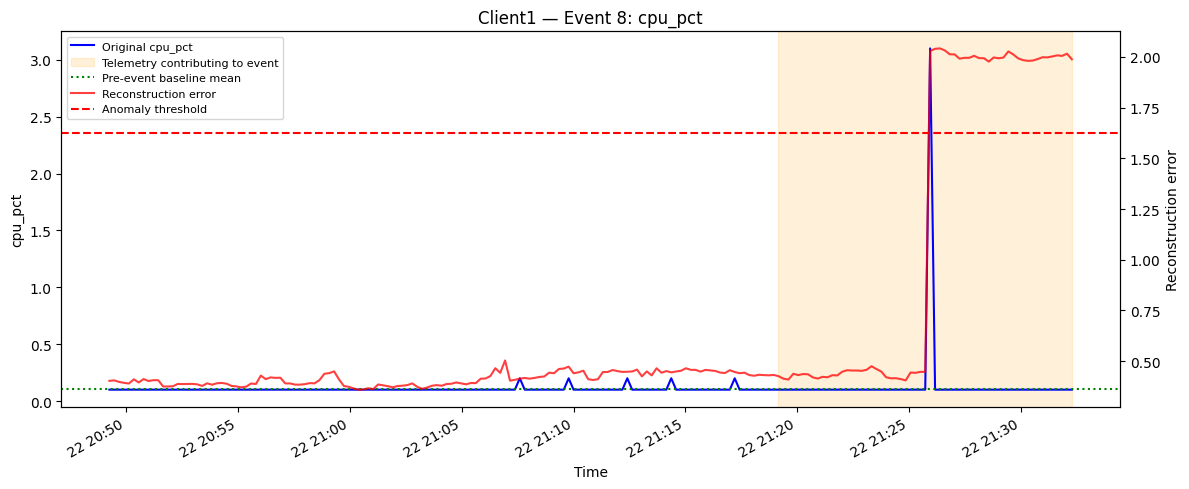

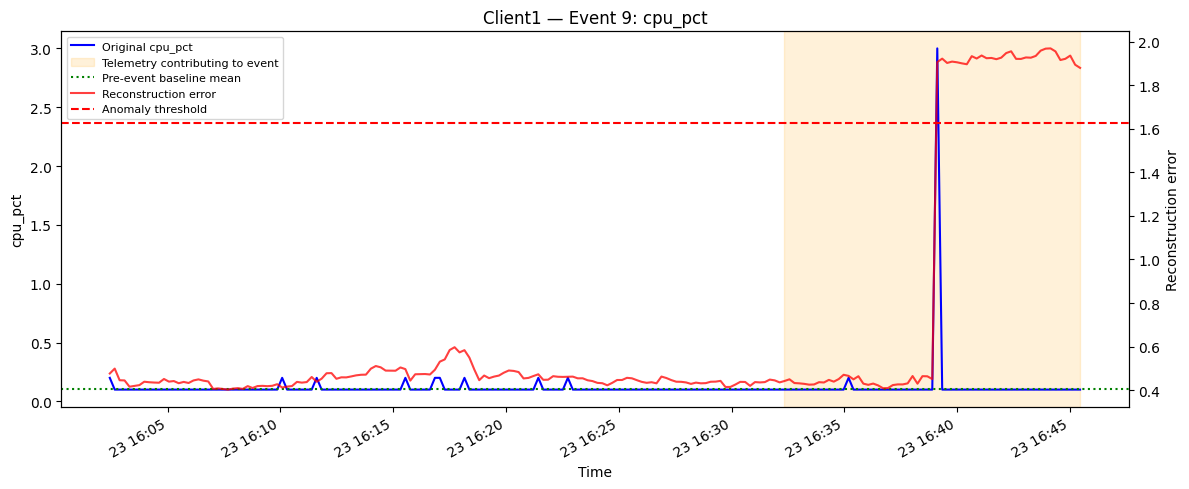

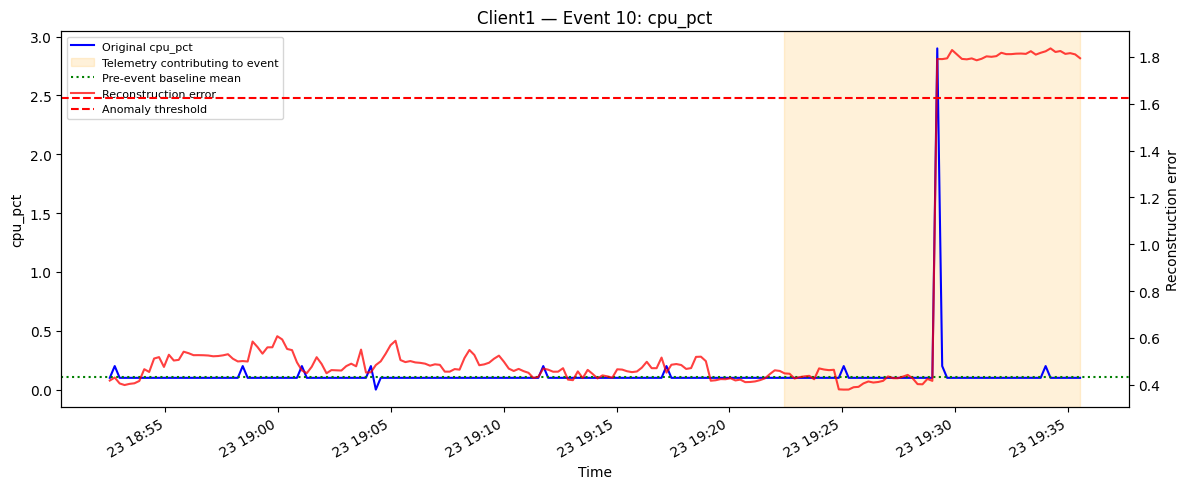

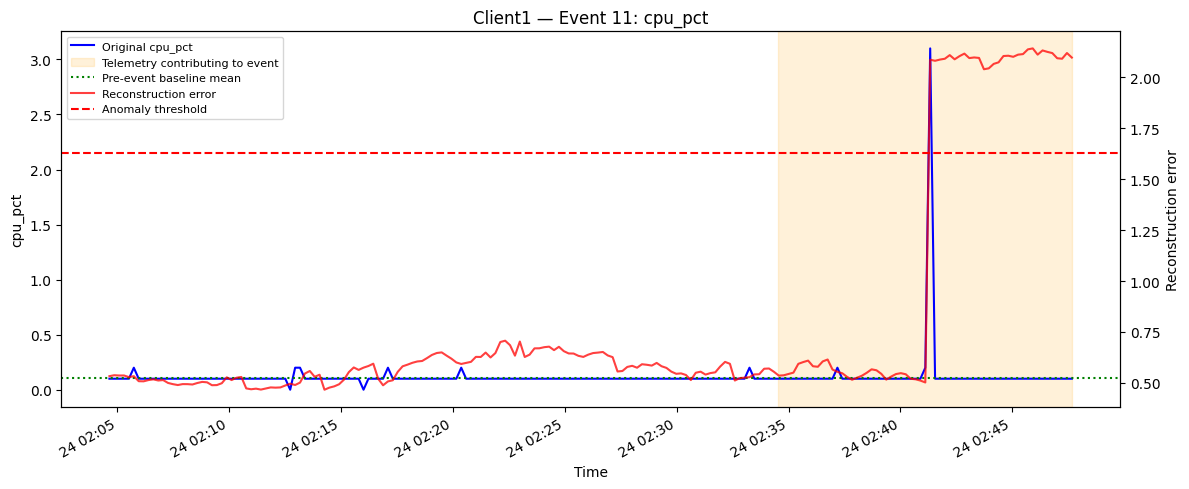

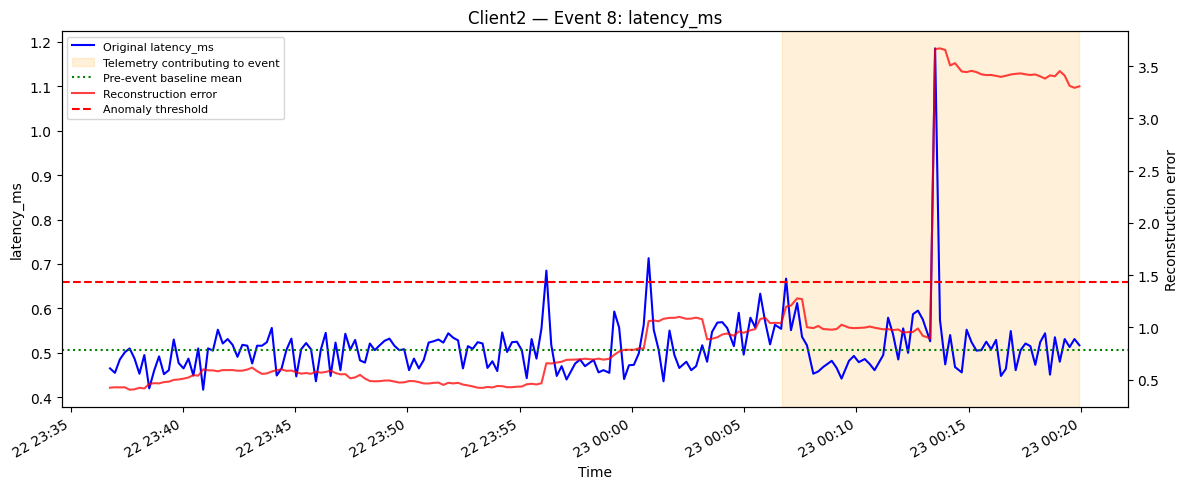

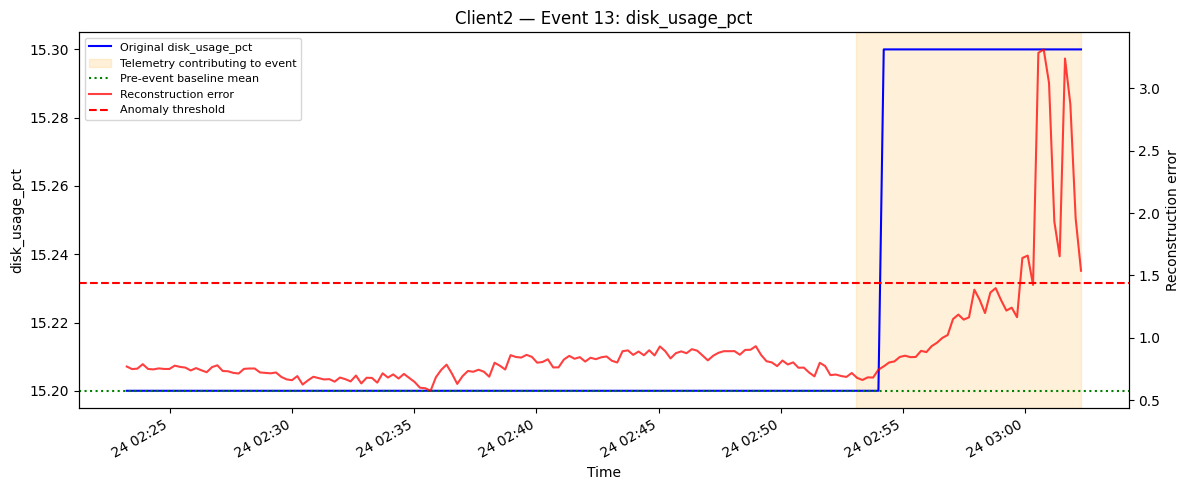

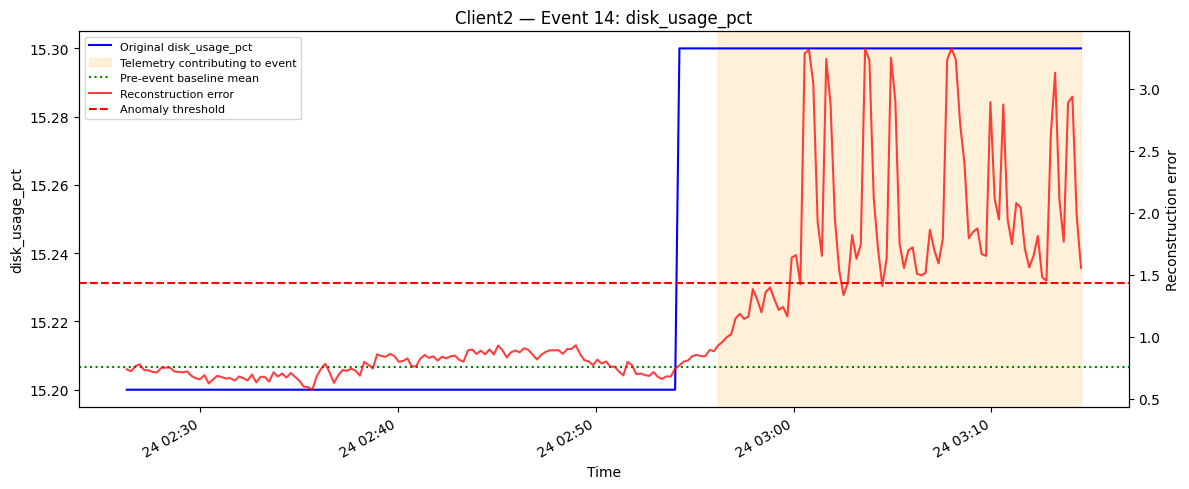

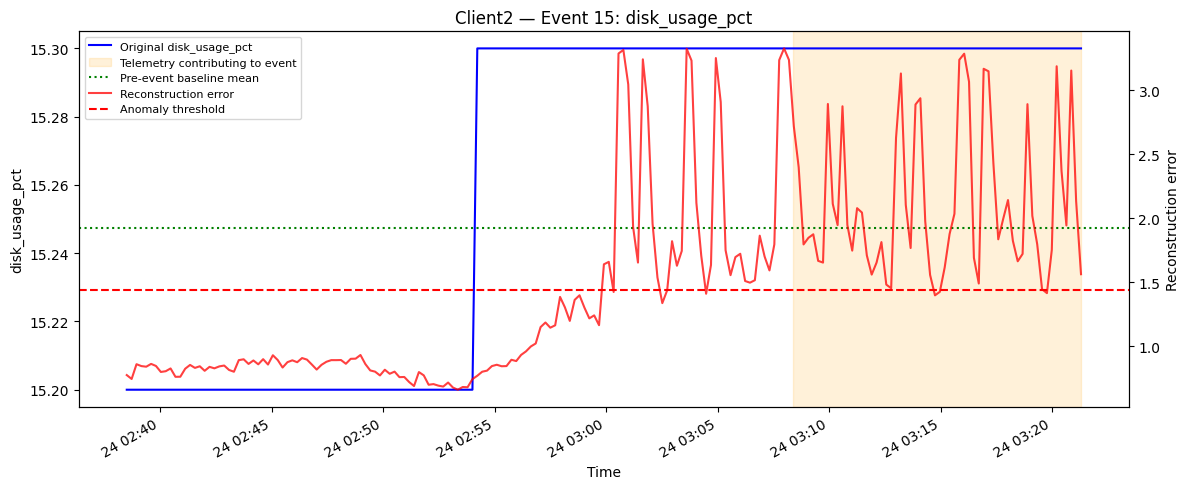

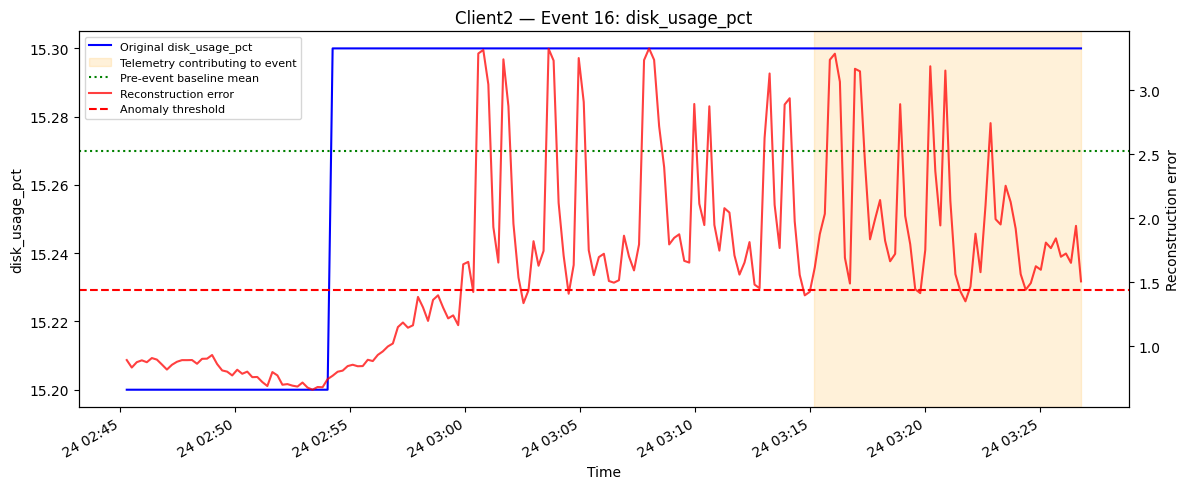

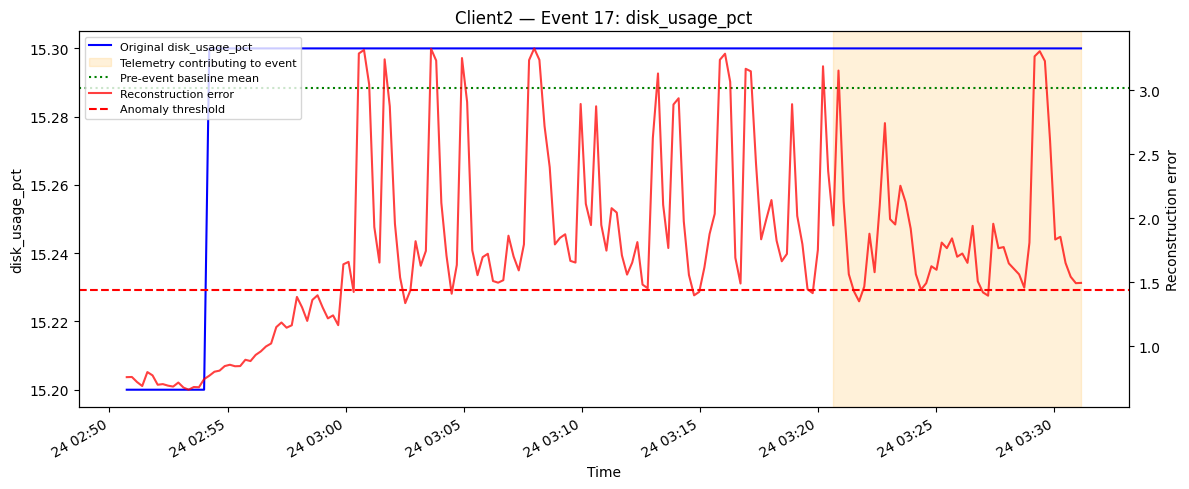

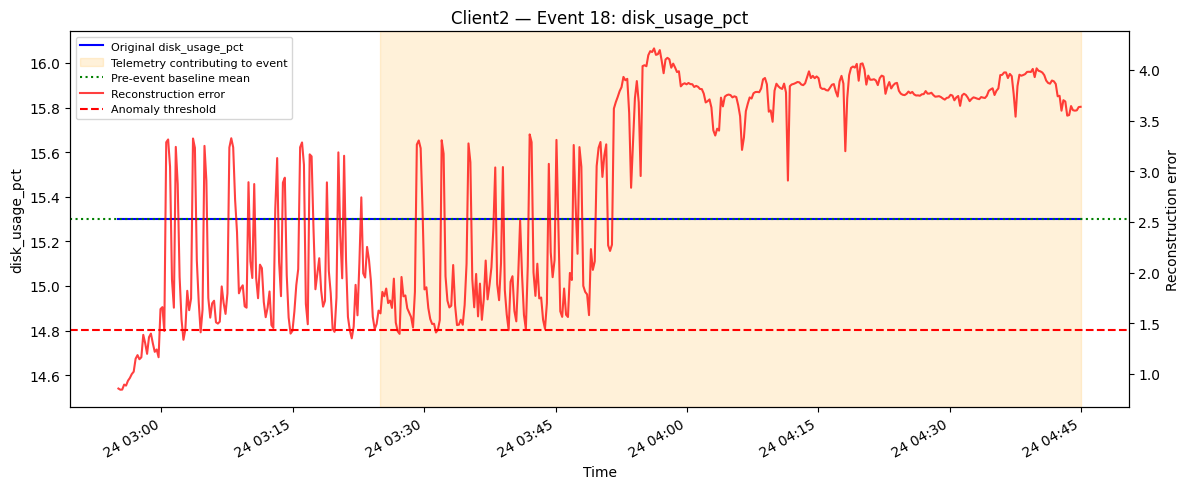

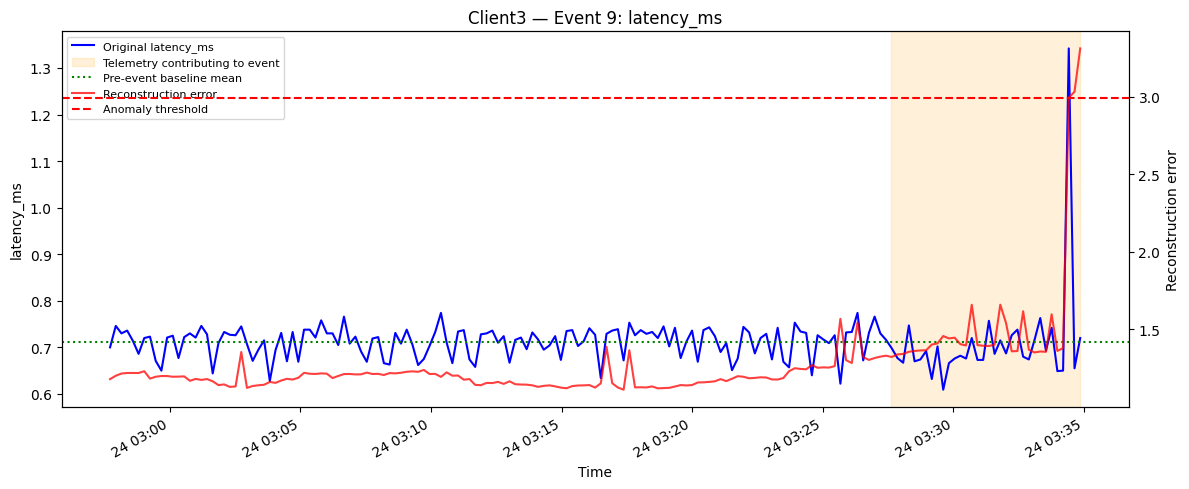

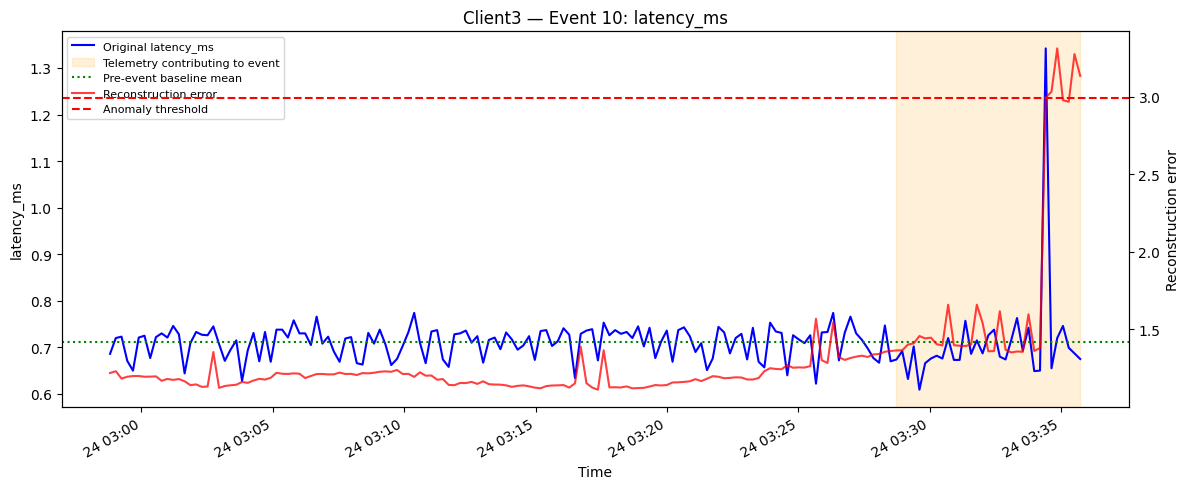

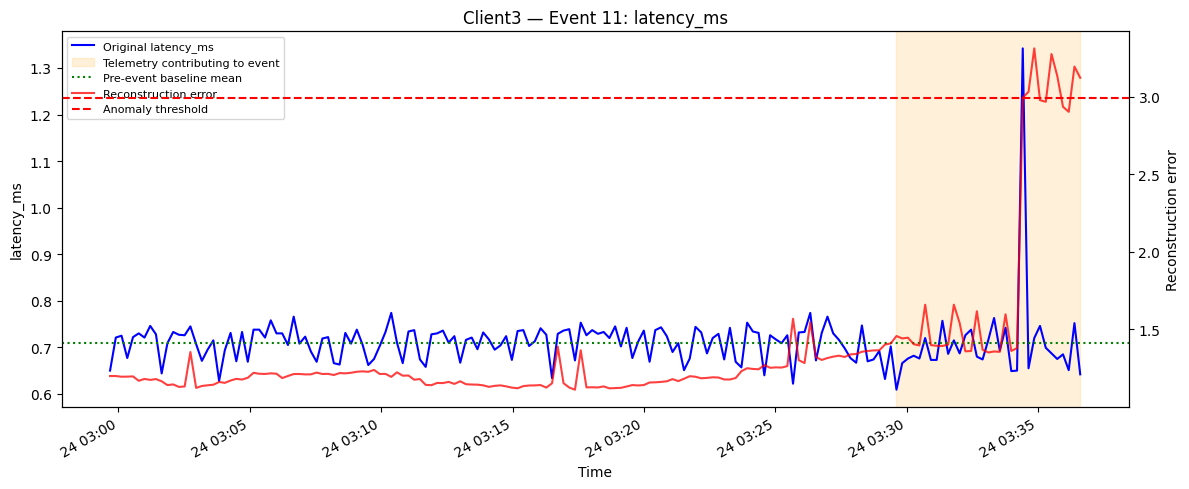

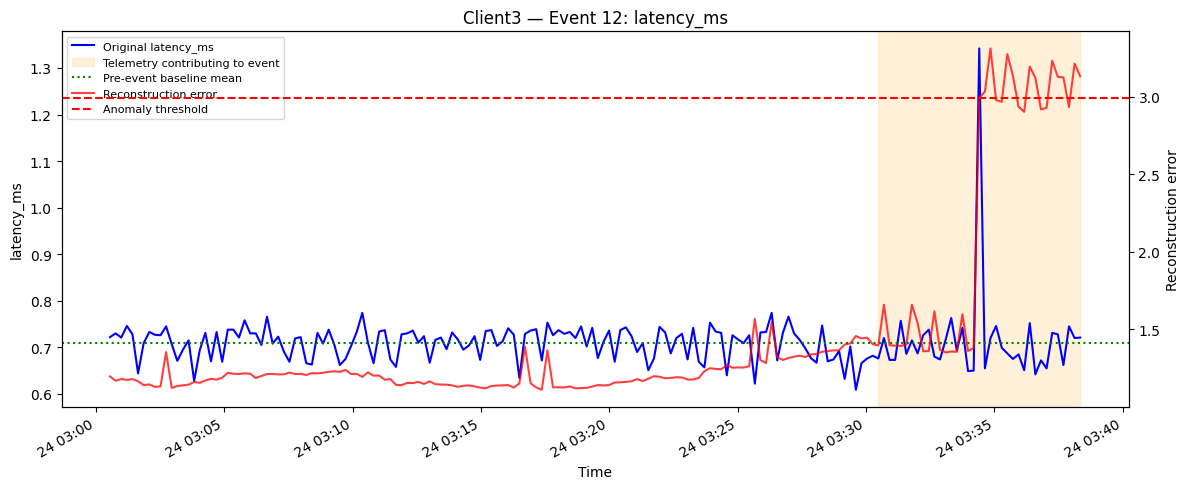

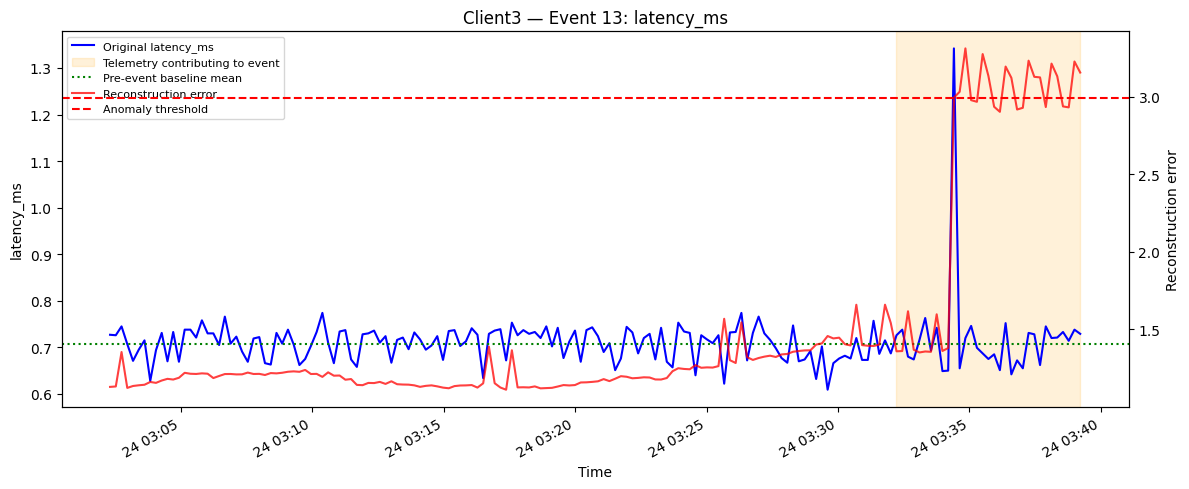

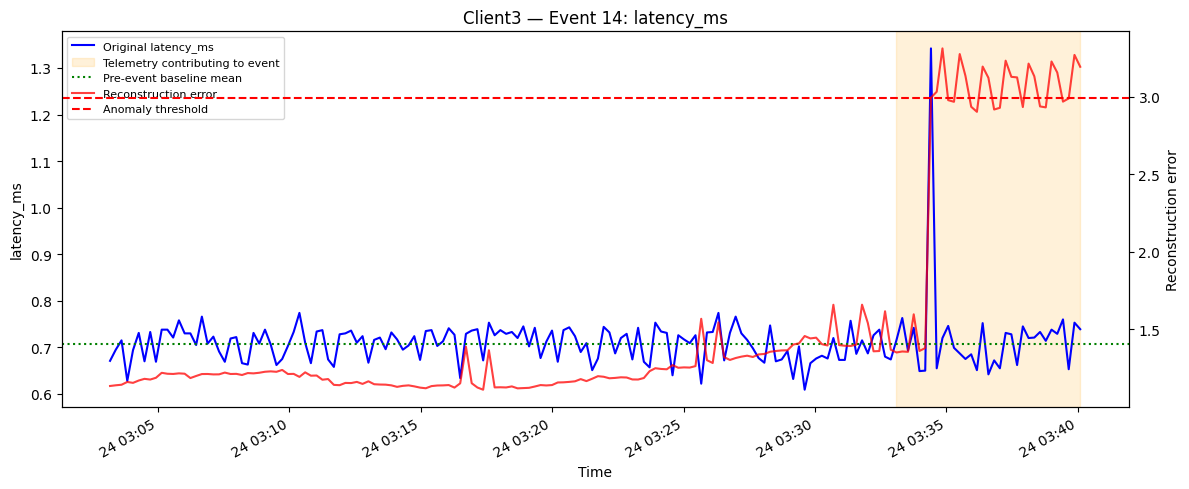

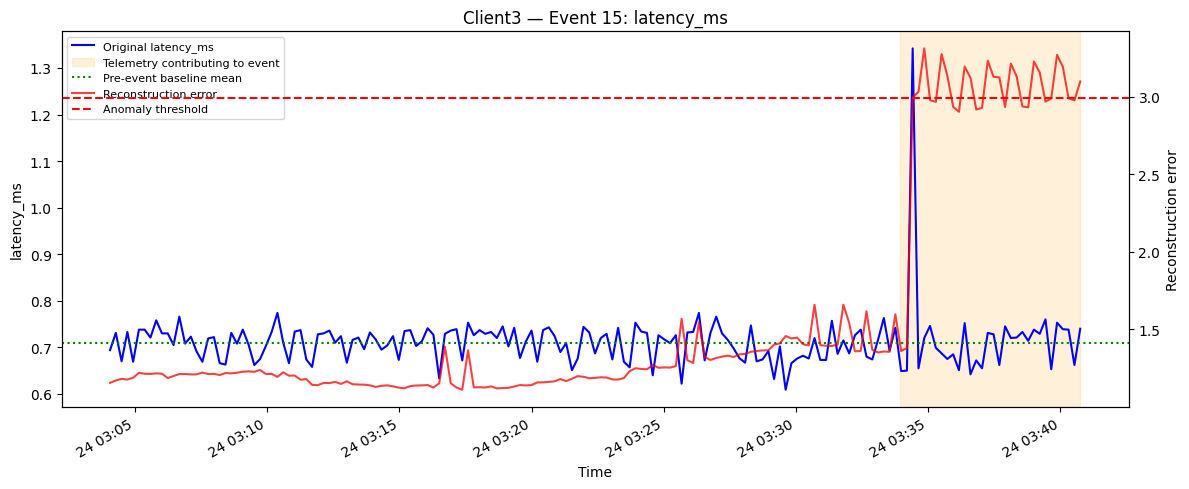

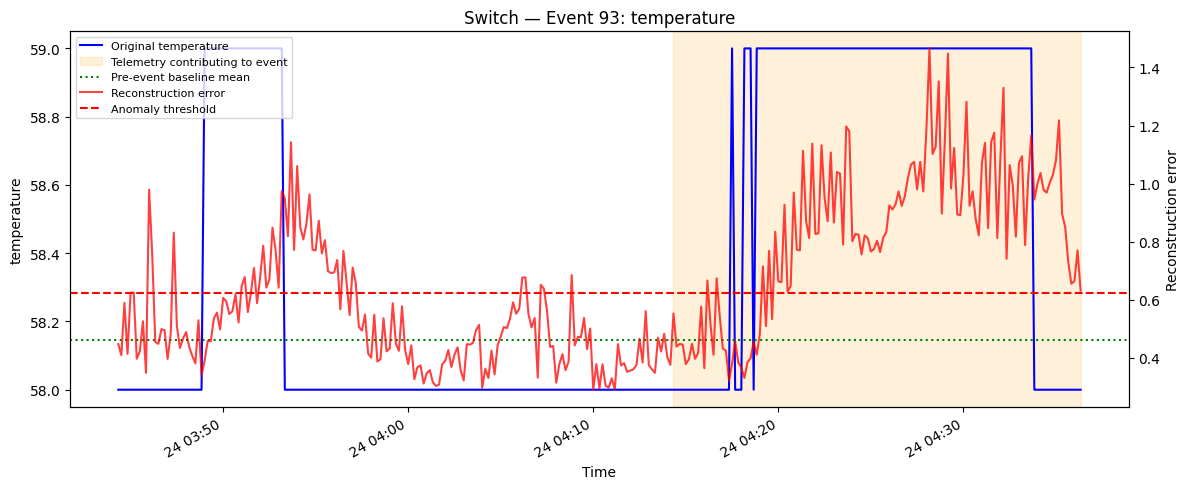

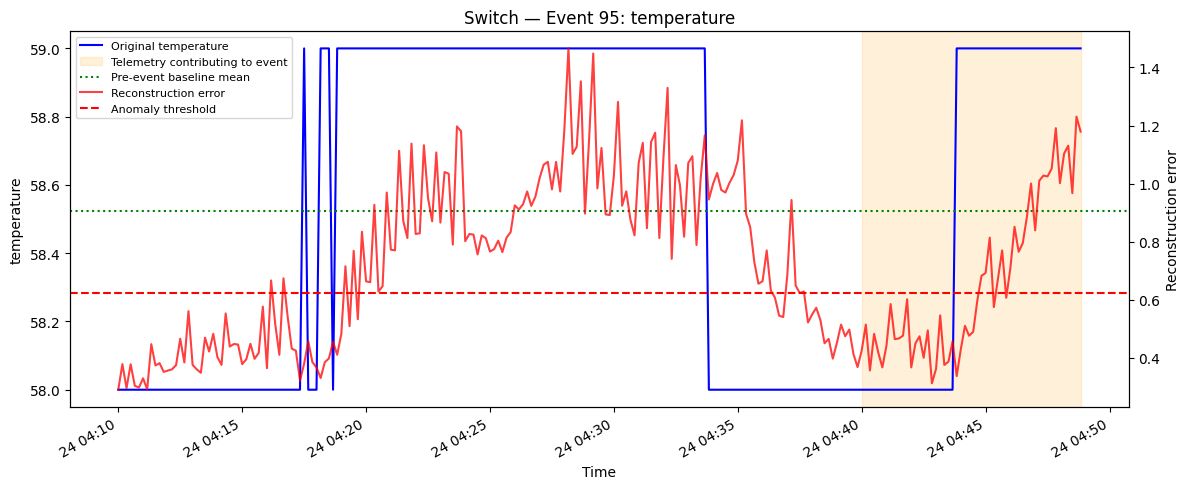


SECTION 8 COMPLETE
 Device  Event_ID         Metric  Baseline_Mean  Event_Mean  Event_Max   Mean_Change  Peak_Severity_Ratio
Client1         1        cpu_pct       0.103650    0.152459      3.100  4.880938e-02             1.327593
Client1         2        cpu_pct       0.122628    0.150820      3.100  2.819193e-02             1.251313
Client1         3        cpu_pct       0.102190    0.149180      3.000  4.699055e-02             1.220436
Client1         4        cpu_pct       0.101460    0.149180      2.900  4.772047e-02             1.165550
Client1         5        cpu_pct       0.105839    0.152459      3.000  4.661960e-02             1.265288
Client1         6        cpu_pct       0.100730    0.152459      3.200  5.172909e-02             1.347130
Client1         7        cpu_pct       0.102190    0.152459      3.200  5.026924e-02             1.341476
Client1         8        cpu_pct       0.103650    0.149180      3.100  4.553069e-02             1.255837
Client1         9        c

In [9]:
# ============================================================
# SECTION 8 — ANOMALY VALIDATION AGAINST ORIGINAL TELEMETRY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 8.1 Configuration
# ------------------------------------------------------------

EVENTS_TO_INSPECT = {
    "Client1": list(range(1, 12)),
    "Client2": [8, 13, 14, 15, 16, 17, 18],
    "Client3": [9, 10, 11, 12, 13, 14, 15],
    "Switch": [93, 95]
}

BASELINE_MINUTES = 30

VALIDATION_DIR = OUTPUT_DIR / "Anomaly_Validation"
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

validation_results = []

# ------------------------------------------------------------
# 8.2 Validate each event
# ------------------------------------------------------------

for device, event_ids in EVENTS_TO_INSPECT.items():

    telemetry = datasets[device].copy()
    events = event_results[device]
    errors = anomaly_results[device].copy()

    telemetry["timestamp"] = pd.to_datetime(
        telemetry["timestamp"], utc=True
    )

    errors["timestamp"] = pd.to_datetime(
        errors["timestamp"], utc=True
    )

    for event_id in event_ids:

        selected = events[
            events["Event_ID"] == event_id
        ]

        if selected.empty:
            print(f"{device}: Event {event_id} not found.")
            continue

        event = selected.iloc[0]

        metric = event["Dominant_Metric"]

        start = pd.Timestamp(event["Start_Time"])
        end = pd.Timestamp(event["End_Time"])

        # Account for the 30-observation LSTM window.
        # This is an approximate window duration.
        sample_seconds = (
            10 if device == "Switch" else 14.07
        )

        window_duration = pd.Timedelta(
            seconds=(SEQUENCE_LENGTH - 1) * sample_seconds
        )

        event_window_start = start - window_duration
        baseline_start = (
            event_window_start
            - pd.Timedelta(minutes=BASELINE_MINUTES)
        )

        # ----------------------------------------------------
        # Baseline and event telemetry
        # ----------------------------------------------------

        baseline = telemetry[
            (telemetry["timestamp"] >= baseline_start) &
            (telemetry["timestamp"] < event_window_start)
        ]

        event_data = telemetry[
            (telemetry["timestamp"] >= event_window_start) &
            (telemetry["timestamp"] <= end)
        ]

        if baseline.empty or event_data.empty:
            print(f"{device} Event {event_id}: insufficient data")
            continue

        baseline_mean = baseline[metric].mean()
        baseline_std = baseline[metric].std()

        event_mean = event_data[metric].mean()
        event_max = event_data[metric].max()
        event_min = event_data[metric].min()

        change = event_mean - baseline_mean

        # ----------------------------------------------------
        # Save quantitative comparison
        # ----------------------------------------------------

        validation_results.append({
            "Device": device,
            "Event_ID": event_id,
            "Metric": metric,
            "Start_Time": start,
            "End_Time": end,
            "Baseline_Mean": baseline_mean,
            "Baseline_Std": baseline_std,
            "Event_Mean": event_mean,
            "Event_Min": event_min,
            "Event_Max": event_max,
            "Mean_Change": change,
            "Peak_Severity_Ratio": event["Peak_Severity_Ratio"]
        })

        # ----------------------------------------------------
        # 8.3 Plot original metric and reconstruction error
        # ----------------------------------------------------

        fig, ax1 = plt.subplots(figsize=(12, 5))

        period = telemetry[
            (telemetry["timestamp"] >= baseline_start) &
            (telemetry["timestamp"] <= end)
        ]

        ax1.plot(
            period["timestamp"],
            period[metric],
            label=f"Original {metric}",
            color="blue"
        )

        ax1.axvspan(
            event_window_start,
            end,
            color="orange",
            alpha=0.15,
            label="Telemetry contributing to event"
        )

        ax1.axhline(
            baseline_mean,
            color="green",
            linestyle=":",
            label="Pre-event baseline mean"
        )

        ax1.set_xlabel("Time")
        ax1.set_ylabel(metric)

        # Reconstruction error on secondary axis
        ax2 = ax1.twinx()

        error_period = errors[
            (errors["timestamp"] >= baseline_start) &
            (errors["timestamp"] <= end)
        ]

        ax2.plot(
            error_period["timestamp"],
            error_period["reconstruction_error"],
            color="red",
            alpha=0.75,
            label="Reconstruction error"
        )

        ax2.axhline(
            event["Threshold"],
            color="red",
            linestyle="--",
            label="Anomaly threshold"
        )

        ax2.set_ylabel("Reconstruction error")

        plt.title(f"{device} — Event {event_id}: {metric}")

        lines1, labels1 = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()

        ax1.legend(
            lines1 + lines2,
            labels1 + labels2,
            loc="upper left",
            fontsize=8
        )

        fig.autofmt_xdate()
        plt.tight_layout()

        plot_path = (
            VALIDATION_DIR /
            f"{device}_Event_{event_id}.png"
        )

        plt.savefig(plot_path, dpi=150)
        plt.show()
        plt.close()

# ============================================================
# 8.4 SAVE VALIDATION SUMMARY
# ============================================================

validation_df = pd.DataFrame(validation_results)

validation_file = (
    VALIDATION_DIR / "Anomaly_Validation_Summary.csv"
)

validation_df.to_csv(validation_file, index=False)

print("\n" + "=" * 60)
print("SECTION 8 COMPLETE")
print("=" * 60)

if not validation_df.empty:
    print(
        validation_df[
            [
                "Device",
                "Event_ID",
                "Metric",
                "Baseline_Mean",
                "Event_Mean",
                "Event_Max",
                "Mean_Change",
                "Peak_Severity_Ratio"
            ]
        ].to_string(index=False)
    )

print("\nResults saved to:", VALIDATION_DIR)

Section 9 - synthetic fault injection and general evaluation

In [10]:
# ============================================================
# SECTION 9 — SYNTHETIC FAULT INJECTION
# MODEL A: ORIGINAL LSTM AUTOENCODER
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tensorflow.keras.models import load_model

# ------------------------------------------------------------
# 9.1 Configuration
# ------------------------------------------------------------

INJECTION_DIR = OUTPUT_DIR / "Fault_Injection"
INJECTION_DIR.mkdir(parents=True, exist_ok=True)

INJECTION_PLOT_DIR = INJECTION_DIR / "Plots"
INJECTION_PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Synthetic test values — not real hardware faults
FAULT_TYPES = {
    "CPU_Overload": {
        "metric": "cpu_pct",
        "value": 85.0
    },
    "High_Latency": {
        "metric": "latency_ms",
        "value": 50.0
    },
    "Packet_Loss": {
        "metric": "packet_loss_pct",
        "value": 20.0
    }
}

FAULT_DURATIONS = {
    "30_seconds": 30,
    "2_minutes": 120,
    "5_minutes": 300
}

# Different positions in the test data
# for the three duration experiments
INJECTION_POSITIONS = {
    "30_seconds": 0.35,
    "2_minutes": 0.55,
    "5_minutes": 0.75
}

BATCH_SIZE_PREDICT = 256

injection_results = []
injection_details = {}


# ------------------------------------------------------------
# 9.2 Calculate reconstruction errors
# ------------------------------------------------------------

def get_reconstruction_errors(model, X):
    """
    Calculate MSE for a batch of LSTM sequences.
    """

    errors = np.empty(len(X), dtype=np.float64)

    for start in range(0, len(X), BATCH_SIZE_PREDICT):

        end = min(start + BATCH_SIZE_PREDICT, len(X))

        batch = X[start:end]

        reconstructed = model.predict(
            batch,
            batch_size=BATCH_SIZE_PREDICT,
            verbose=0
        )

        errors[start:end] = np.mean(
            (
                batch.astype(np.float64)
                - reconstructed.astype(np.float64)
            ) ** 2,
            axis=(1, 2)
        )

    return errors


# ------------------------------------------------------------
# 9.3 Process devices
# ------------------------------------------------------------

for device in sequence_data:

    print("\n" + "=" * 60)
    print(f"DEVICE: {device}")
    print("=" * 60)

    metrics = list(sequence_data[device]["metrics"])

    # Load existing trained model
    model = (
        models[device]
        if device in models
        else load_model(
            MODEL_DIR / f"{device}_LSTM_Autoencoder.keras"
        )
    )

    # Load existing fitted scaler
    scaler = scalers[device]

    # Original, scaled test observations from Section 3
    X_test_scaled = split_data[device]["test"]

    raw_timestamps = pd.to_datetime(
        split_data[device]["test_timestamps"],
        utc=True
    )

    # Convert to original physical measurement units
    raw_test = scaler.inverse_transform(
        X_test_scaled
    )

    # Valid sequence-ending timestamps from Section 4
    sequence_timestamps = pd.to_datetime(
        sequence_data[device]["test_timestamps"],
        utc=True
    )

    # Map valid sequence endings back to original test rows
    raw_times_ns = raw_timestamps.asi8
    sequence_times_ns = sequence_timestamps.asi8

    end_indices = np.searchsorted(
        raw_times_ns,
        sequence_times_ns
    )

    # Verify timestamp alignment
    assert np.all(end_indices < len(raw_test))
    assert np.array_equal(
        raw_times_ns[end_indices],
        sequence_times_ns
    ), f"Timestamp mismatch for {device}"

    assert np.all(
        end_indices >= SEQUENCE_LENGTH - 1
    ), f"Insufficient sequence history for {device}"

    # Load existing baseline reconstruction errors
    baseline_df = anomaly_results[device].copy()

    baseline_df["timestamp"] = pd.to_datetime(
        baseline_df["timestamp"],
        utc=True
    )

    baseline_df = baseline_df.set_index("timestamp")

    # Align with the exact valid sequence timestamps
    aligned = baseline_df.reindex(sequence_timestamps)

    if aligned["reconstruction_error"].isna().any():
        raise ValueError(
            f"Missing baseline errors for {device}"
        )

    baseline_errors = aligned[
        "reconstruction_error"
    ].to_numpy(dtype=float)

    threshold = float(anomaly_thresholds[device])

    # --------------------------------------------------------
    # 9.4 Inject synthetic faults
    # --------------------------------------------------------

    for fault_name, fault_config in FAULT_TYPES.items():

        metric = fault_config["metric"]
        injected_value = fault_config["value"]

        # Skip unsupported metrics
        if metric not in metrics:
            continue

        metric_index = metrics.index(metric)

        for duration_name, duration_seconds in (
            FAULT_DURATIONS.items()
        ):

            # Choose injection start in the test period
            position = INJECTION_POSITIONS[duration_name]

            start_index = int(
                len(raw_test) * position
            )

            start_time = raw_timestamps[start_index]

            requested_end_time = (
                start_time
                + pd.Timedelta(seconds=duration_seconds)
            )

            # Select original observations within fault period
            injection_mask = (
                (raw_timestamps >= start_time)
                & (raw_timestamps < requested_end_time)
            )

            injected_rows = np.flatnonzero(
                np.asarray(injection_mask)
            )

            if len(injected_rows) == 0:
                continue

            first_row = int(injected_rows[0])
            last_row = int(injected_rows[-1])

            # ------------------------------------------------
            # Create modified copy in ORIGINAL units
            # ------------------------------------------------

            modified_raw = raw_test.copy()

            modified_raw[
                injected_rows,
                metric_index
            ] = injected_value

            # Apply the EXISTING training scaler.
            # Never fit another scaler here.
            modified_scaled = scaler.transform(
                modified_raw
            ).astype(np.float32)

            # ------------------------------------------------
            # Find valid LSTM sequences touched by injection
            # ------------------------------------------------

            sequence_starts = (
                end_indices - SEQUENCE_LENGTH + 1
            )

            affected_mask = (
                (end_indices >= first_row)
                & (sequence_starts <= last_row)
            )

            affected_indices = np.flatnonzero(
                affected_mask
            )

            if len(affected_indices) == 0:
                continue

            # Build only the affected sequences.
            # Reuse the original valid sequence endings,
            # preserving Section 4's timestamp-gap exclusions.
            offsets = np.arange(
                SEQUENCE_LENGTH - 1,
                -1,
                -1
            )

            window_rows = (
                end_indices[affected_indices, None]
                - offsets[None, :]
            )

            X_modified = modified_scaled[
                window_rows
            ]

            # ------------------------------------------------
            # 9.5 Run the existing LSTM model
            # ------------------------------------------------

            injected_errors = get_reconstruction_errors(
                model,
                X_modified
            )

            original_errors = baseline_errors[
                affected_indices
            ]

            # Anomaly detections
            original_flags = original_errors > threshold
            injected_flags = injected_errors > threshold

            # New detections attributable to changed inputs
            newly_detected = (
                injected_flags & ~original_flags
            )

            detected = bool(injected_flags.any())
            new_detection = bool(newly_detected.any())

            # ------------------------------------------------
            # 9.6 Detection delay
            # ------------------------------------------------

            affected_times = sequence_timestamps[
                affected_indices
            ]

            actual_end_time = raw_timestamps[last_row]

            if detected:
                first_detection_time = affected_times[
                    np.flatnonzero(injected_flags)[0]
                ]
                detection_delay = (
                    first_detection_time - start_time
                ).total_seconds()
            else:
                detection_delay = np.nan

            if new_detection:
                first_new_time = affected_times[
                    np.flatnonzero(newly_detected)[0]
                ]
                new_detection_delay = (
                    first_new_time - start_time
                ).total_seconds()
            else:
                new_detection_delay = np.nan

            # ------------------------------------------------
            # 9.7 Store results
            # ------------------------------------------------

            peak_error = float(
                np.max(injected_errors)
            )

            peak_original_error = float(
                np.max(original_errors)
            )

            peak_severity = peak_error / max(
                threshold, 1e-12
            )

            result = {
                "Device": device,
                "Fault_Type": fault_name,
                "Metric": metric,
                "Injected_Value": injected_value,
                "Duration_Seconds": duration_seconds,
                "Injection_Start": start_time,
                "Injection_End": actual_end_time,
                "Modified_Observations": len(injected_rows),
                "Affected_Sequences": len(affected_indices),
                "Baseline_Anomalous_Sequences": int(
                    original_flags.sum()
                ),
                "Injected_Anomalous_Sequences": int(
                    injected_flags.sum()
                ),
                "Newly_Anomalous_Sequences": int(
                    newly_detected.sum()
                ),
                "Detected": detected,
                "Newly_Detected": new_detection,
                "Detection_Delay_Seconds": detection_delay,
                "New_Detection_Delay_Seconds":
                    new_detection_delay,
                "Threshold": threshold,
                "Peak_Original_Error": peak_original_error,
                "Peak_Injected_Error": peak_error,
                "Peak_Severity_Ratio": peak_severity
            }

            injection_results.append(result)

            experiment_key = (
                device,
                fault_name,
                duration_name
            )

            injection_details[experiment_key] = {
                "timestamps": affected_times,
                "original_errors": original_errors,
                "injected_errors": injected_errors,
                "threshold": threshold,
                "start_time": start_time,
                "end_time": actual_end_time
            }

            print(
                f"{fault_name:15} | "
                f"{duration_name:10} | "
                f"Detected: {detected!s:5} | "
                f"New: {new_detection!s:5} | "
                f"Peak: {peak_error:.3f}"
            )


# ============================================================
# 9.8 SAVE EXPERIMENT RESULTS
# ============================================================

injection_df = pd.DataFrame(injection_results)

injection_file = (
    INJECTION_DIR / "Fault_Injection_Results.csv"
)

injection_df.to_csv(
    injection_file,
    index=False
)

print("\n" + "=" * 60)
print("SECTION 9 — FAULT INJECTION COMPLETE")
print("=" * 60)

print("\nIndividual Test Results:")

print(
    injection_df[
        [
            "Device",
            "Fault_Type",
            "Duration_Seconds",
            "Detected",
            "Newly_Detected",
            "New_Detection_Delay_Seconds",
            "Peak_Severity_Ratio"
        ]
    ].to_string(index=False)
)

print("\nSaved to:", injection_file)


DEVICE: Client1
CPU_Overload    | 30_seconds | Detected: True  | New: True  | Peak: 3815.721
CPU_Overload    | 2_minutes  | Detected: True  | New: True  | Peak: 12718.045
CPU_Overload    | 5_minutes  | Detected: True  | New: True  | Peak: 29248.272
High_Latency    | 30_seconds | Detected: True  | New: True  | Peak: 40541.656


C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-pac

High_Latency    | 2_minutes  | Detected: True  | New: True  | Peak: 135146.421
High_Latency    | 5_minutes  | Detected: True  | New: True  | Peak: 310697.106
Packet_Loss     | 30_seconds | Detected: True  | New: True  | Peak: 6.226
Packet_Loss     | 2_minutes  | Detected: True  | New: True  | Peak: 19.728
Packet_Loss     | 5_minutes  | Detected: True  | New: True  | Peak: 45.013

DEVICE: Client2


C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-pac

CPU_Overload    | 30_seconds | Detected: True  | New: True  | Peak: 2807.010
CPU_Overload    | 2_minutes  | Detected: True  | New: True  | Peak: 9360.470
CPU_Overload    | 5_minutes  | Detected: True  | New: True  | Peak: 21516.273
High_Latency    | 30_seconds | Detected: True  | New: True  | Peak: 43658.541
High_Latency    | 2_minutes  | Detected: True  | New: True  | Peak: 145528.514


...

C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-pac

CPU_Overload    | 5_minutes  | Detected: True  | New: True  | Peak: 13328.566
High_Latency    | 30_seconds | Detected: True  | New: True  | Peak: 30225.873
High_Latency    | 2_minutes  | Detected: True  | New: True  | Peak: 100724.256
High_Latency    | 5_minutes  | Detected: True  | New: True  | Peak: 231670.425
Packet_Loss     | 30_seconds | Detected: True  | New: True  | Peak: 6.356
Packet_Loss     | 2_minutes  | Detected: True  | New: True  | Peak: 19.735


C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-pac

Packet_Loss     | 5_minutes  | Detected: True  | New: True  | Peak: 44.770

DEVICE: Switch
CPU_Overload    | 30_seconds | Detected: True  | New: True  | Peak: 138.734
CPU_Overload    | 2_minutes  | Detected: True  | New: True  | Peak: 547.787
CPU_Overload    | 5_minutes  | Detected: True  | New: True  | Peak: 1367.383

SECTION 9 — FAULT INJECTION COMPLETE

Individual Test Results:
 Device   Fault_Type  Duration_Seconds  Detected  Newly_Detected  New_Detection_Delay_Seconds  Peak_Severity_Ratio
Client1 CPU_Overload                30      True            True                     0.000000          2346.262058
Client1 CPU_Overload               120      True            True                     0.000000          7820.243152
Client1 CPU_Overload               300      True            True                     0.000000         17984.572912
Client1 High_Latency                30      True            True                     0.000000         24928.800884
Client1 High_Latency               120   

C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
C:\Users\alwyn\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
